# GELAR RASA 2026 — EDA, preprocessing, modeling, dan submission

Notebook tunggal ini membaca 1.920 foto train dan 480 foto test, memeriksa data, menghasilkan delapan folder train eligible, melatih tiga classifier pada fitur DINOv2 beku, mengevaluasi dengan fold kelompok sumber, lalu membuat tiga CSV submission. Seluruh model classifier dilatih di notebook ini; bobot DINOv2 non-VLM yang diverifikasi dipakai hanya sebagai feature extractor.

Panitia tidak memberikan label train. Sebagian besar kategori train adalah assignment algoritmis terdahulu, bukan ground truth resmi. Sebanyak 19 sumber train yang ditahan tidak masuk fit. Evaluasi terhadap target otomatis hanya diagnostik dan bukan Accuracy resmi. Test tidak pernah dipakai untuk training, tuning, atau koreksi kategori. Semua output disusun mengikuti urutan sample submission.

In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from collections import Counter
import os, sys, json, hashlib, time, platform, html
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import imagehash
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

STARTED = time.time()
SEED = 20261106
np.random.seed(SEED)
CLASSES = ['glass', 'paper', 'electronic', 'metal', 'plastic', 'cardboard', 'textile', 'foodwaste']
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = Path(os.environ['GELAR_PROJECT_ROOT']).resolve() if 'GELAR_PROJECT_ROOT' in os.environ else next(
    (p for p in candidates if (p / 'data/Dataset DSC GelarRasa 2026').exists()), Path.cwd())
DATA = Path(os.environ.get('GELAR_DATA_DIR', str(ROOT / 'data'))).resolve()
RAW = DATA / 'Dataset DSC GelarRasa 2026'
MAX_WORKERS = min(4, os.cpu_count() or 1)
PROCESSED = ROOT / 'data/processed'
PROFILE_HOME = PROCESSED
PROFILE_HOME.mkdir(parents=True, exist_ok=True)
INPUT_PATH = DATA / 'preprocessing_inputs.npz'
assert INPUT_PATH.is_file(), 'Input snapshot preprocessing belum tersedia.'

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''): h.update(block)
    return h.hexdigest()

def relative(path):
    path = Path(path).resolve()
    try: return path.relative_to(ROOT).as_posix()
    except ValueError: return str(path)

def resolve(path):
    path = Path(path)
    return path if path.is_absolute() else ROOT / path

def rgb_image(path):
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(source)
        if 'A' in im.getbands() or 'transparency' in im.info:
            rgba = im.convert('RGBA')
            im = Image.alpha_composite(Image.new('RGBA', rgba.size, (255, 255, 255, 255)), rgba)
        return im.convert('RGB').copy()


import re

FIGURES = ROOT / 'final-submit/reports'
FINAL_OUTPUT = ROOT / 'final-submit/output'
FIGURES.mkdir(parents=True, exist_ok=True)
FINAL_OUTPUT.mkdir(parents=True, exist_ok=True)
figure_exports = []

def publish_figure():
    figure = plt.gcf()
    title = figure._suptitle.get_text() if figure._suptitle else ' '.join(ax.get_title() for ax in figure.axes[:3])
    stem = re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_')[:85] or 'visualisasi_eda'
    path = FIGURES / f'{len(figure_exports) + 1:02d}_{stem}.png'
    figure.savefig(path, dpi=130, bbox_inches='tight')
    figure_exports.append({'path': relative(path), 'title': title, 'sha256': digest(path)})
    plt.show()
    plt.close(figure)


def gallery(frame, title, pathcol='source_path', limit=12, columns=4, caption=None):
    frame = frame.head(limit)
    if frame.empty:
        display(Markdown(title + ': tidak ada contoh pada kondisi ini.')); return
    rows = int(np.ceil(len(frame) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 2.8 * rows), squeeze=False, dpi=85)
    for ax in axes.flat: ax.axis('off')
    for ax, row in zip(axes.flat, frame.to_dict('records')):
        im = rgb_image(resolve(row[pathcol])); im.thumbnail((300, 260))
        ax.imshow(im)
        label = caption(row) if caption else f"{row.get('split', '')} {row.get('image_id', row.get('sample_id', ''))}"
        ax.set_title(label, fontsize=9)
    fig.suptitle(title, fontsize=13); fig.tight_layout(); publish_figure()

environment = {'python': sys.version, 'platform': platform.platform(), 'seed': SEED,
               'packages': {p: metadata.version(p) for p in ['numpy', 'pandas', 'Pillow', 'ImageHash', 'opencv-python', 'matplotlib']}}
print('Root:', ROOT)
print('Data:', RAW)
print('Interpreter:', sys.executable)
print('Lingkup: EDA + preprocessing; training baru: False')
display(pd.Series(environment['packages'], name='versi pustaka'))

Root: D:\lomba\NSC UB\GELAR-RASA
Data: D:\lomba\NSC UB\GELAR-RASA\data\Dataset DSC GelarRasa 2026
Interpreter: D:\lomba\NSC UB\GELAR-RASA\.venv\Scripts\python.exe
Lingkup: EDA + preprocessing; training baru: False


numpy               2.2.6
pandas              2.3.3
Pillow             12.2.0
ImageHash           4.3.2
opencv-python    5.0.0.93
matplotlib         3.10.8
Name: versi pustaka, dtype: object

## 1. Inventaris data dan integritas ID

Train dibaca dari file langsung di folder train, sehingga salinan pada subfolder tidak dihitung dua kali. Urutan test dibentuk dari ID numerik nama file di folder test dataset. Kekurangan, kelebihan atau ID ganda menghentikan pemrosesan.

In [2]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}
records = []
for split, width in [('train', 4), ('test', 3)]:
    directory = RAW / split
    files = sorted([p for p in directory.iterdir() if p.is_file() and p.suffix.lower() in EXTENSIONS], key=lambda p: int(p.stem))
    for path in files:
        assert path.stem.isdigit()
        image_id = str(int(path.stem)).zfill(width)
        records.append({'key': f'{split}:{image_id}', 'split': split, 'image_id': image_id,
                        'filename': path.name, 'source_path': relative(path)})
inventory = pd.DataFrame(records)
assert inventory.key.is_unique
assert inventory.groupby('split').size().to_dict() == {'test': 480, 'train': 1920}
assert set(inventory.loc[inventory.split.eq('train'), 'image_id']) == {f'{i:04d}' for i in range(1, 1921)}
test_order = sorted(inventory.loc[inventory.split.eq('test'), 'image_id'].astype(str).tolist(), key=int)
assert len(test_order) == len(set(test_order)) == 480
assert set(test_order) == set(inventory.loc[inventory.split.eq('test'), 'image_id'])
with ThreadPoolExecutor(MAX_WORKERS) as pool:
    inventory['source_sha256'] = list(pool.map(lambda p: digest(resolve(p)), inventory.source_path))
display(inventory.groupby('split').agg(gambar=('key', 'size'), ID_unik=('image_id', 'nunique')))
print('File dalam subfolder train tidak dienumerasi sebagai sampel tambahan.')

,gambar,ID_unik
split,,
test,480,480
train,1920,1920


File dalam subfolder train tidak dienumerasi sebagai sampel tambahan.


## 2. Profil piksel, format, ukuran, dan kualitas

Seluruh file didekode. Orientasi EXIF diterapkan sekali, transparansi dikompositkan pada putih, lalu RGB. Hash byte berbeda makna dari hash piksel terdekode. Brightness/contrast/saturation memakai rentang 0–1. Entropy, Laplacian dan edge fraction dihitung pada tampilan maksimal 256 piksel dengan rasio tetap.

Nilai Laplacian rendah dapat berasal dari permukaan polos; nilai ini tidak otomatis berarti gambar buruk. Ambang kualitas berikut hanya indikator EDA, tanpa penghapusan otomatis. Cache hanya digunakan bila ID dan seluruh hash byte sumber identik.

In [3]:
def profile_one(row):
    record = dict(row)
    try:
        path = resolve(row['source_path'])
        with Image.open(path) as source:
            record.update(source_format=source.format, source_mode=source.mode,
                          original_width=source.width, original_height=source.height,
                          exif_orientation=int(source.getexif().get(274, 1)),
                          has_alpha=('A' in source.getbands() or 'transparency' in source.info),
                          n_frames=int(getattr(source, 'n_frames', 1)))
        im = rgb_image(path)
        small = ImageOps.contain(im, (256, 256), method=Image.Resampling.LANCZOS)
        gray = np.asarray(small.convert('L'))
        rgb = np.asarray(small).astype(np.float32) / 255
        probabilities = np.bincount(gray.ravel(), minlength=256).astype(float) / gray.size
        probabilities = probabilities[probabilities > 0]
        record.update(byte_size=path.stat().st_size, width=im.width, height=im.height,
                      aspect_ratio=im.width / im.height, megapixels=im.width * im.height / 1e6,
                      pixel_sha256=hashlib.sha256(im.tobytes()).hexdigest(),
                      brightness=float(gray.mean() / 255), contrast=float(gray.std() / 255),
                      saturation=float(np.asarray(small.convert('HSV'))[:, :, 1].mean() / 255),
                      entropy_bits=float(-(probabilities * np.log2(probabilities)).sum()),
                      laplacian_variance_256=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                      edge_fraction=float((cv2.Canny(gray, 100, 200) > 0).mean()),
                      dark_fraction=float((gray < 13).mean()), bright_fraction=float((gray > 242).mean()),
                      phash=str(imagehash.phash(im)), phash_hflip=str(imagehash.phash(ImageOps.mirror(im))),
                      phash_vflip=str(imagehash.phash(ImageOps.flip(im))), dhash=str(imagehash.dhash(im)),
                      decode_status='ok', decode_error='')
    except Exception as exc:
        record.update(decode_status='error', decode_error=repr(exc))
    return record

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    profile = pd.DataFrame(pool.map(profile_one, inventory.to_dict('records')))
failures = profile[profile.decode_status.ne('ok')]
display(failures)
assert len(profile) == 2400 and failures.empty, 'Ada sumber gagal decode; pemrosesan dihentikan.'
print('Seluruh 2.400 gambar diprofilkan dari sumber pada run ini.')

display(profile.groupby(['split', 'source_format', 'source_mode']).size().rename('jumlah').reset_index())
display(profile.groupby('split')[['width', 'height', 'aspect_ratio', 'megapixels', 'byte_size']].describe().round(3))
display(profile.groupby(['split', 'width', 'height']).size().rename('jumlah').reset_index().sort_values('jumlah', ascending=False).head(20))

,key,split,image_id,filename,source_path,source_sha256,source_format,source_mode,original_width,original_height,...,laplacian_variance_256,edge_fraction,dark_fraction,bright_fraction,phash,phash_hflip,phash_vflip,dhash,decode_status,decode_error


Seluruh 2.400 gambar diprofilkan dari sumber pada run ini.


,split,source_format,source_mode,jumlah
0,test,JPEG,RGB,479
1,test,PNG,RGB,1
2,train,JPEG,RGB,1918
3,train,PNG,P,1
4,train,PNG,RGBA,1


width                                                        height  \
        count     mean      std    min    25%    50%    75%     max   count   
split                                                                         
test    480.0  500.269  162.473  129.0  416.0  416.0  640.0  1600.0   480.0   
train  1920.0  549.182  259.502  100.0  416.0  509.0  640.0  2605.0  1920.0   

                ... megapixels        byte_size                                \
          mean  ...        75%    max     count       mean        std     min   
split           ...                                                             
test   479.754  ...       0.41  1.867     480.0  32772.173  54329.621  3114.0   
train  545.208  ...       0.41  9.145    1920.0  42886.840  89056.203  2132.0   

                                               
            25%      50%       75%        max  
split                                          
test   14518.25  22512.5  37670.75   885324.0  
train  15925.50  24924.5  42983.50  2689277.0  

[2 rows x 40 columns]

,split,width,height,jumlah
169,train,640,640,700
144,train,416,416,579
25,test,416,416,240
31,test,640,640,136
132,train,400,533,74
168,train,640,480,74
210,train,1599,1599,57
111,train,320,320,56
72,train,225,225,39
133,train,400,534,36


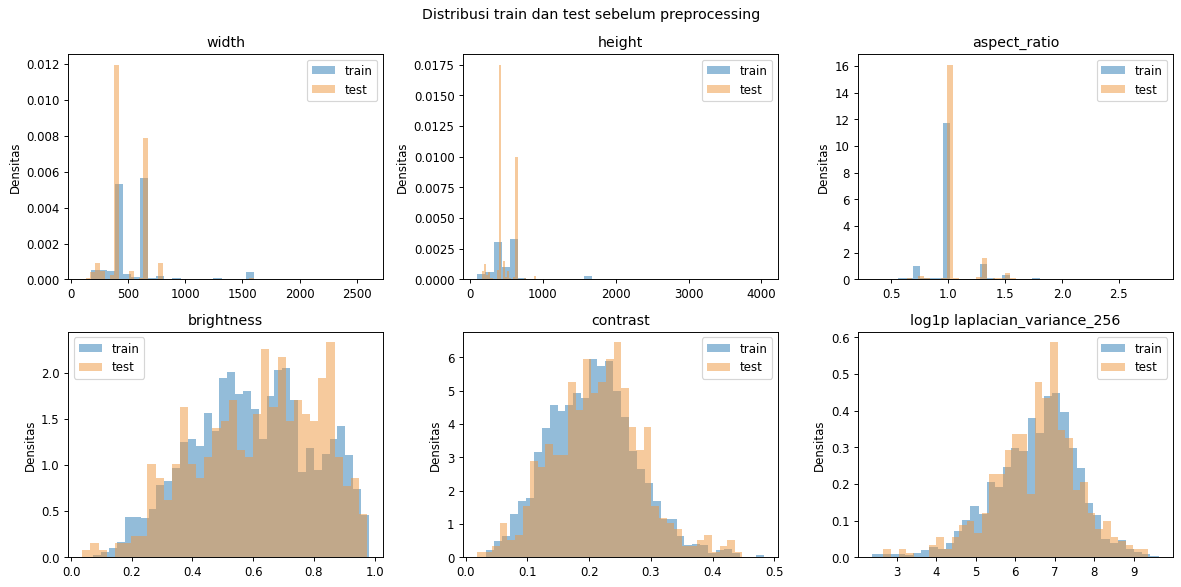

low_sharpness        53.647638
high_edge_density     0.276302
low_brightness        0.204253
high_brightness       0.943374
Name: ambang deskriptif dari train, dtype: float64

,low_sharpness_indicator,dense_edges_indicator,extreme_brightness_indicator
split,,,
test,8,6,16
train,39,39,78


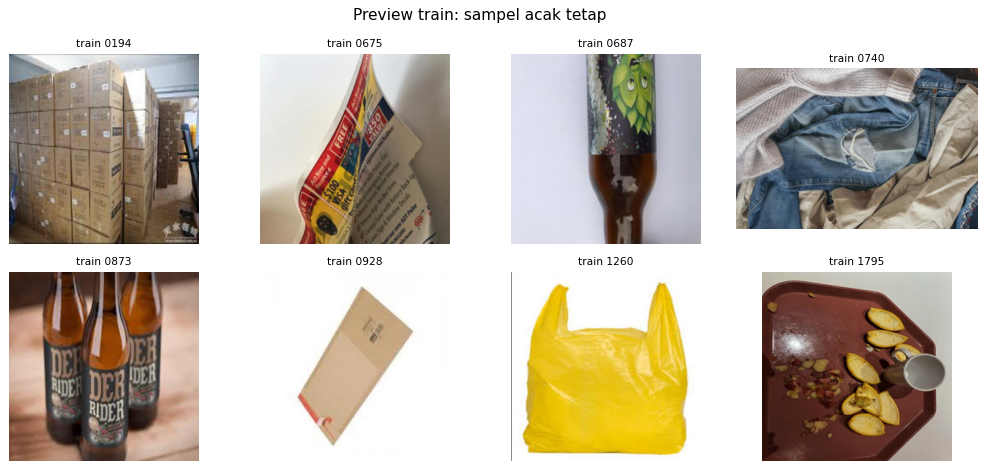

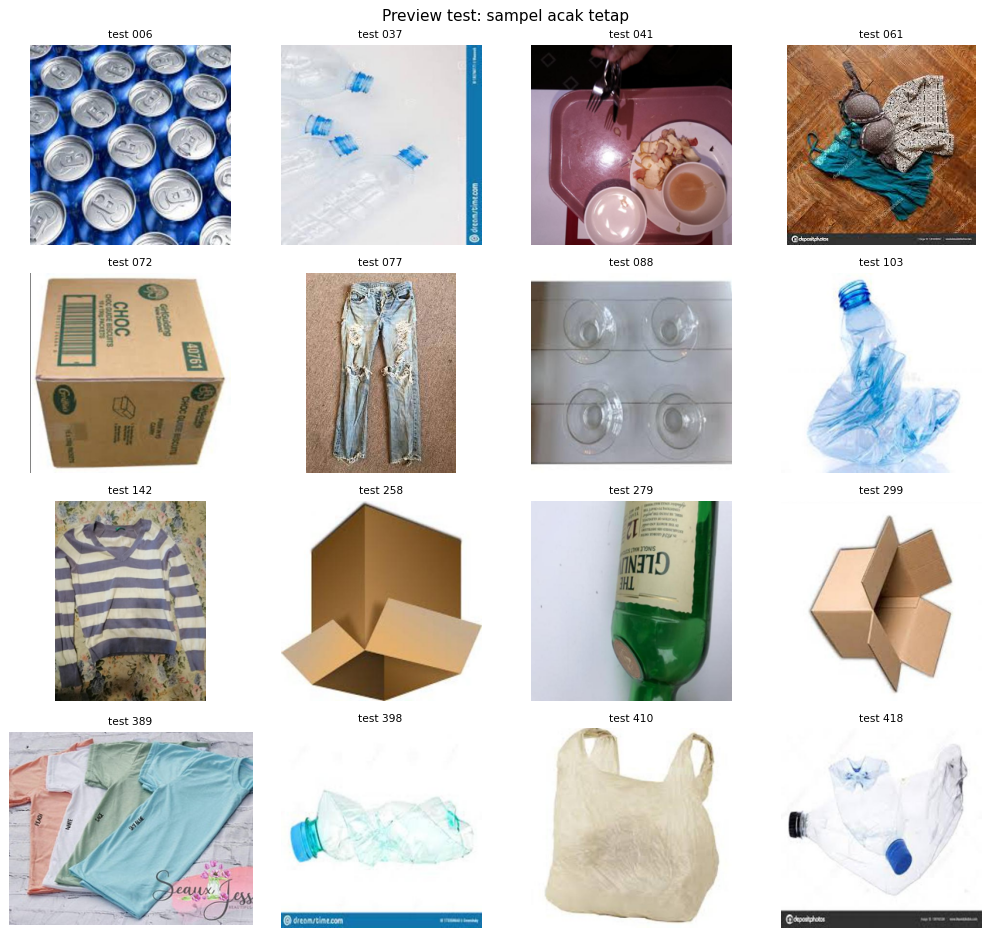

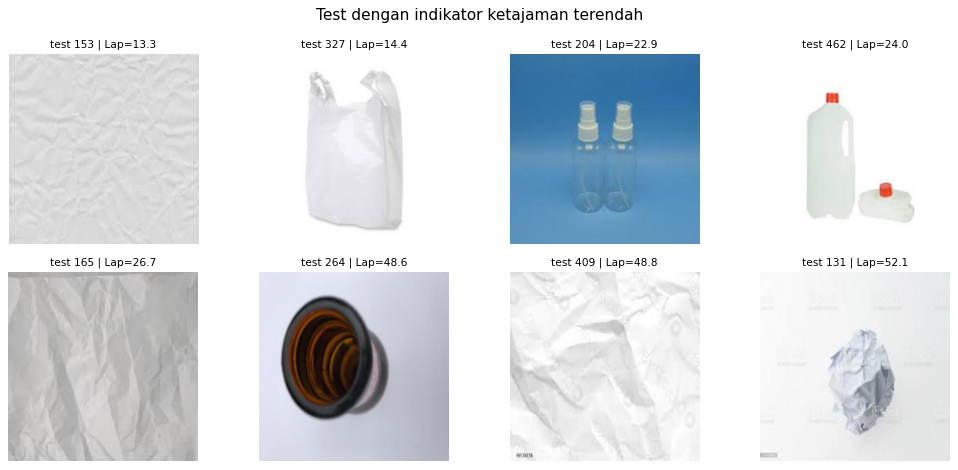

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), dpi=85)
for ax, column in zip(axes.flat, ['width', 'height', 'aspect_ratio', 'brightness', 'contrast', 'laplacian_variance_256']):
    for split, color in [('train', '#287bb5'), ('test', '#ef963d')]:
        values = profile.loc[profile.split.eq(split), column]
        values = np.log1p(values) if column == 'laplacian_variance_256' else values
        ax.hist(values, bins=35, alpha=.5, density=True, label=split, color=color)
    ax.set_title(('log1p ' if column == 'laplacian_variance_256' else '') + column)
    ax.set_ylabel('Densitas'); ax.legend()
fig.suptitle('Distribusi train dan test sebelum preprocessing'); fig.tight_layout(); publish_figure()

train_profile = profile[profile.split.eq('train')]
thresholds = {'low_sharpness': float(train_profile.laplacian_variance_256.quantile(.02)),
              'high_edge_density': float(train_profile.edge_fraction.quantile(.98)),
              'low_brightness': float(train_profile.brightness.quantile(.02)),
              'high_brightness': float(train_profile.brightness.quantile(.98))}
profile['low_sharpness_indicator'] = profile.laplacian_variance_256.le(thresholds['low_sharpness'])
profile['dense_edges_indicator'] = profile.edge_fraction.ge(thresholds['high_edge_density'])
profile['extreme_brightness_indicator'] = profile.brightness.le(thresholds['low_brightness']) | profile.brightness.ge(thresholds['high_brightness'])
display(pd.Series(thresholds, name='ambang deskriptif dari train'))
display(profile.groupby('split')[['low_sharpness_indicator', 'dense_edges_indicator', 'extreme_brightness_indicator']].sum())
gallery(profile[profile.split.eq('train')].sample(8, random_state=SEED).sort_values('image_id'), 'Preview train: sampel acak tetap', limit=8)
gallery(profile[profile.split.eq('test')].sample(16, random_state=SEED).sort_values('image_id'), 'Preview test: sampel acak tetap', limit=16)
gallery(profile[profile.split.eq('test')].nsmallest(8, 'laplacian_variance_256'), 'Test dengan indikator ketajaman terendah', limit=8,
        caption=lambda r: f"test {r['image_id']} | Lap={r['laplacian_variance_256']:.1f}")

## 3. Duplikat dan kemiripan train–test

Duplikat byte dan piksel diperiksa secara terpisah. Kesamaan piksel mensyaratkan ukuran yang sama. Pencarian pHash membandingkan setiap test dengan **seluruh train**, memakai minimum jarak Hamming pada tiga orientasi train: asli, horizontal flip, dan vertical flip. Ini bukan pencarian rotasi penuh atau bukti kesamaan bahan.

Ukuran identik dan pHash kecil hanya petunjuk; keduanya tidak menjadi label test. Pasangan terdekat diekspor untuk seluruh 480 test, disertai kesamaan ukuran dan hash piksel. Data test tidak dimasukkan ke train.

Anggota kelompok duplikat byte: **8**; piksel: **8**.

,key,width,height,pixel_sha256
847,train:0848,640,640,1f93428a09c7e418b8dcc24f2c813a41450e0ee3dd0976...
1716,train:1717,640,640,1f93428a09c7e418b8dcc24f2c813a41450e0ee3dd0976...
1961,test:042,640,640,fbef0ca5c3569f5528e55db389a951a2a8e3549eddc382...
1820,train:1821,640,640,fbef0ca5c3569f5528e55db389a951a2a8e3549eddc382...
2120,test:201,674,900,4bc0f7e4a1d9c5df21e890193293c9cea8c65a67793a93...
1134,train:1135,674,900,4bc0f7e4a1d9c5df21e890193293c9cea8c65a67793a93...
1936,test:017,800,533,8bb5e5af2d21ba8963e2d50a1043aa528b0396ee36ea71...
1045,train:1046,800,533,8bb5e5af2d21ba8963e2d50a1043aa528b0396ee36ea71...


count    480.000000
mean      14.354167
std        4.211474
min        0.000000
25%       14.000000
50%       16.000000
75%       16.000000
max       20.000000
Name: phash_hamming, dtype: float64

,test_id,train_id,rank,phash_hamming,same_native_size,same_decoded_pixels,test_width,test_height,train_width,train_height,test_path,train_path
48,017,1046,1,0,True,True,800,533,800,533,data/Dataset DSC GelarRasa 2026/test/017.jpg,data/Dataset DSC GelarRasa 2026/train/1046.jpg
78,027,1874,1,0,False,False,416,416,277,182,data/Dataset DSC GelarRasa 2026/test/027.jpg,data/Dataset DSC GelarRasa 2026/train/1874.jpg
123,042,1821,1,0,True,True,640,640,640,640,data/Dataset DSC GelarRasa 2026/test/042.jpg,data/Dataset DSC GelarRasa 2026/train/1821.jpg
198,067,0271,1,0,True,False,640,640,640,640,data/Dataset DSC GelarRasa 2026/test/067.jpg,data/Dataset DSC GelarRasa 2026/train/0271.jpg
207,070,0682,1,0,False,False,201,251,416,416,data/Dataset DSC GelarRasa 2026/test/070.jpg,data/Dataset DSC GelarRasa 2026/train/0682.jpg
222,075,1726,1,0,False,False,640,640,259,194,data/Dataset DSC GelarRasa 2026/test/075.jpg,data/Dataset DSC GelarRasa 2026/train/1726.jpg
360,121,1754,1,0,False,False,416,416,640,640,data/Dataset DSC GelarRasa 2026/test/121.jpg,data/Dataset DSC GelarRasa 2026/train/1754.jpg
468,157,0012,1,0,True,False,640,640,640,640,data/Dataset DSC GelarRasa 2026/test/157.jpg,data/Dataset DSC GelarRasa 2026/train/0012.jpg
519,174,0210,1,0,False,False,416,416,640,640,data/Dataset DSC GelarRasa 2026/test/174.jpg,data/Dataset DSC GelarRasa 2026/train/0210.jpg
600,201,1135,1,0,True,True,674,900,674,900,data/Dataset DSC GelarRasa 2026/test/201.jpg,data/Dataset DSC GelarRasa 2026/train/1135.jpg


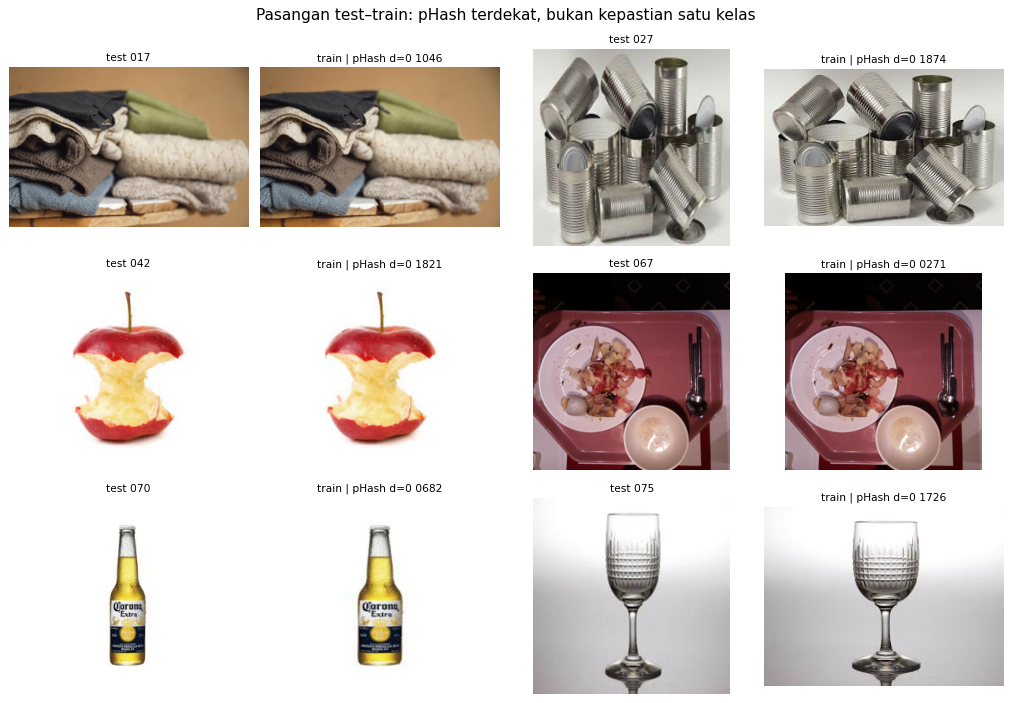

In [5]:
byte_duplicates = profile[profile.duplicated('source_sha256', keep=False)].sort_values(['source_sha256', 'key'])
pixel_cols = ['width', 'height', 'pixel_sha256']
pixel_duplicates = profile[profile.duplicated(pixel_cols, keep=False)].sort_values(pixel_cols + ['key'])
display(Markdown(f'Anggota kelompok duplikat byte: **{len(byte_duplicates)}**; piksel: **{len(pixel_duplicates)}**.'))
display(pixel_duplicates[['key', 'width', 'height', 'pixel_sha256']])

tr = profile[profile.split.eq('train')].reset_index(drop=True)
te = profile[profile.split.eq('test')].reset_index(drop=True)
train_hashes = [[int(r[c], 16) for c in ['phash', 'phash_hflip', 'phash_vflip']] for r in tr.to_dict('records')]
nearest_rows = []
for query in te.to_dict('records'):
    q = int(query['phash'], 16)
    distances = np.array([min((q ^ h).bit_count() for h in variants) for variants in train_hashes], dtype=np.int16)
    for rank, position in enumerate(np.argsort(distances, kind='stable')[:3], 1):
        candidate = tr.iloc[position]
        same_size = query['width'] == candidate.width and query['height'] == candidate.height
        nearest_rows.append({'test_id': query['image_id'], 'train_id': candidate.image_id, 'rank': rank,
                             'phash_hamming': int(distances[position]), 'same_native_size': bool(same_size),
                             'same_decoded_pixels': bool(same_size and query['pixel_sha256'] == candidate.pixel_sha256),
                             'test_width': query['width'], 'test_height': query['height'],
                             'train_width': candidate.width, 'train_height': candidate.height,
                             'test_path': query['source_path'], 'train_path': candidate.source_path})
nearest = pd.DataFrame(nearest_rows)
assert nearest.test_id.nunique() == 480 and len(nearest) == 1440
display(nearest[nearest['rank'].eq(1)].phash_hamming.describe())
display(nearest.sort_values(['phash_hamming', 'test_id', 'rank']).head(15))
best = nearest[nearest['rank'].eq(1)].sort_values(['phash_hamming', 'test_id']).head(6)
paired = []
for row in best.to_dict('records'):
    paired += [{'image_id': row['test_id'], 'split': 'test', 'source_path': row['test_path'], 'note': 'test'},
               {'image_id': row['train_id'], 'split': 'train', 'source_path': row['train_path'], 'note': f"train | pHash d={row['phash_hamming']}"}]
gallery(pd.DataFrame(paired), 'Pasangan test–train: pHash terdekat, bukan kepastian satu kelas', limit=12,
        caption=lambda r: f"{r['note']} {r['image_id']}")

## 4. Input kategori algoritmis dan integritas sumber

Snapshot memuat kategori foto utuh dari proses sebelumnya. Penyempurnaan memakai representasi objek dan material serta source group terpisah. Tahap classifier/graph dan cluster dilanjutkan dengan head neural yang diadaptasi pada train: loss ordinary cross-entropy untuk acuan manusia dan generalized cross-entropy untuk target otomatis. Tahap terbaru menambahkan representasi ViT image-only, kNN yang dipilih berdasarkan diagnostik acuan, dan label propagation train-only. Perubahan harus didukung beberapa bank fitur dan graph, bukan keputusan manual per ID. Seluruh skor tetap belum terkalibrasi. Kategori acuan manusia dicatat secara eksplisit. Test tidak dipakai dalam fit. Penahanan noise terbaru berlaku untuk training classifier berikutnya; assignment historis dalam snapshot tidak dihitung ulang pada run ini.

Sel ini memeriksa kecocokan ID dan hash sumber; tidak melatih ulang proses tersebut atau menganggap assignment sebagai ground truth. Skor adalah skor program, dukungan keluarga, atau indikator asal review manusia; bukan probabilitas terkalibrasi. Jumlah acuan manusia, sisa kapasitas dan kategorinya ditampilkan terpisah, maksimal lima foto sumber per kategori. Foto 1215 termasuk acuan cardboard yang dinyatakan tim, bukan perubahan otomatis yang disamarkan. Setiap tahap memiliki kriteria penerimaan tersendiri. Tahap classifier historis memeriksa dua pembobotan prior; tahap kNN memakai persetujuan bank fitur serta pemeriksaan kedekatan, dengan graph train-only pada tahap yang memakainya. Tahap pseudo-acuan saat ini dapat memakai kategori program terdahulu sebagai target lemah; konsistensi antarpseudo-label tidak menjadi validasi kebenaran kategori yang independen. Metode aktif dan kriterianya tercatat pada metadata snapshot; kriteria historis tidak diklaim sebagai pengujian ulang tahap terbaru. Perbaikan ontology pencahayaan memakai nama sumber yang spesifik dan pemeriksaan flip. Foto yang ditahan dipisahkan dari folder train final saat materialisasi. Crop dinilai terpisah pada tahap materialisasi.

,acuan_manusia_per_kategori,batas_per_kategori,sisa_kapasitas
assigned_class,,,
glass,5,5,0
paper,5,5,0
electronic,5,5,0
metal,3,5,2
plastic,5,5,0
cardboard,5,5,0
textile,5,5,0
foodwaste,2,5,3


Metode snapshot: unchanged_frozen_residual_router_batch_continuation_v1


split,test,train
predicted_class,,
glass,57,250
paper,47,232
electronic,60,202
metal,65,236
plastic,60,251
cardboard,57,259
textile,68,309
foodwaste,66,181


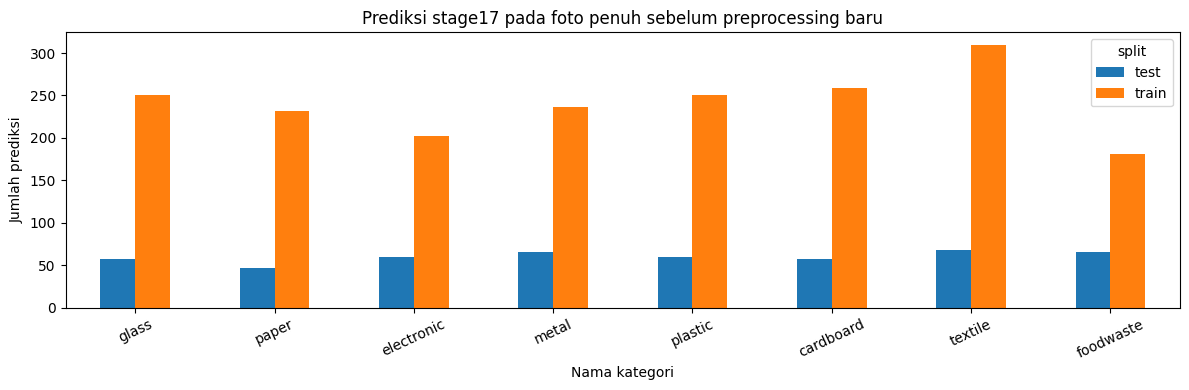

,gambar,flag_tinjau,confidence_margin_rendah,konflik_sumber_saja
split,,,,
test,480,126,25,101
train,1920,655,416,271


Flag tinjau adalah diagnostik; bukan jumlah gambar tanpa kategori atau jumlah salah terverifikasi.


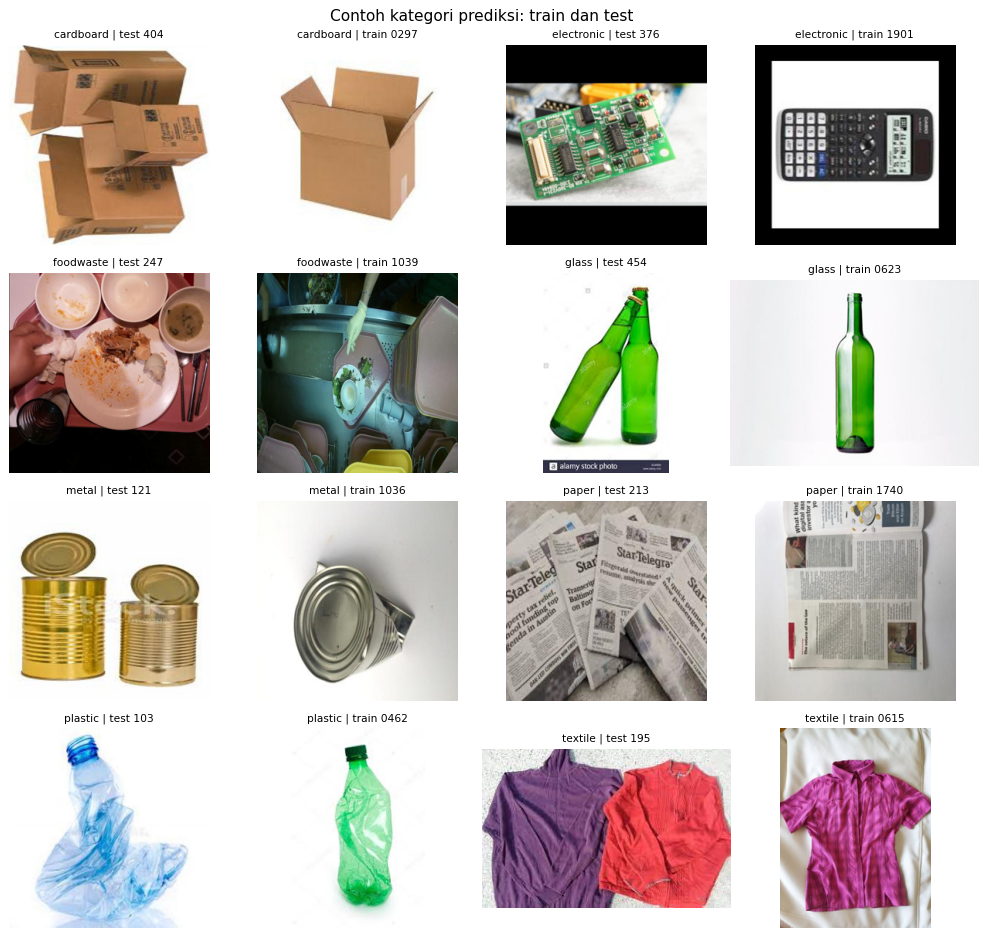

In [6]:
input_bundle = np.load(INPUT_PATH, allow_pickle=False)
input_metadata = json.loads(str(input_bundle['metadata'].item()))
input_table = pd.DataFrame({'key':input_bundle['keys'], 'source_sha256':input_bundle['source_sha256'],
                            'candidate_group':input_bundle['groups'], 'predicted_class':input_bundle['predicted_class'],
                            'uncalibrated_probability':input_bundle['confidence'], 'margin':input_bundle['margin'],
                            'needs_review':input_bundle['needs_review'], 'cnn_prior_disagrees':input_bundle['cnn_prior_disagrees']})
input_table['category_source'] = input_bundle['category_source'] if 'category_source' in input_bundle else 'historical_routing_snapshot'
input_table['category_score_kind'] = input_bundle['category_score_kind'] if 'category_score_kind' in input_bundle else 'historical_uncalibrated_program_score'
assert len(input_table)==2400 and input_table.key.is_unique and set(input_table.key)==set(inventory.key)
matched = inventory[['key','source_sha256']].merge(input_table[['key','source_sha256']], on='key', validate='one_to_one', suffixes=('_raw','_input'))
assert matched.source_sha256_raw.eq(matched.source_sha256_input).all()
assert input_table.predicted_class.isin(CLASSES).all()
human_input = pd.DataFrame({'key':input_bundle['human_seed_keys'], 'assigned_class':input_bundle['human_seed_labels'],
                            'source_sha256':input_bundle['human_seed_source_sha256']}) if 'human_seed_keys' in input_bundle else pd.DataFrame(columns=['key','assigned_class','source_sha256'])
assert human_input.key.is_unique and human_input.key.str.startswith('train:').all()
assert human_input.assigned_class.isin(CLASSES).all()
human_counts = human_input.assigned_class.value_counts().reindex(CLASSES,fill_value=0)
assert len(human_input)<=40 and human_counts.le(5).all()
if len(human_input):
    human_check = human_input.merge(input_table[['key','predicted_class','source_sha256','category_source']],on='key',validate='one_to_one',suffixes=('_human','_input'))
    assert human_check.assigned_class.eq(human_check.predicted_class).all()
    assert human_check.source_sha256_human.eq(human_check.source_sha256_input).all()
    assert human_check.category_source.eq('participant_reviewed_seed').all()
    human_input['origin']='participant_reviewed_train'
    human_input.to_csv(PROCESSED/'manual_seeds.csv',index=False)
human_keys = set(human_input.key)
deferred_keys = set(input_metadata.get('deferred_train_keys', []))
assert deferred_keys <= set(input_table.key) and all(k.startswith('train:') for k in deferred_keys)
cleaning_keys = set(input_metadata.get('train_cleaning_exclusion_keys', []))
assert cleaning_keys <= deferred_keys and not cleaning_keys.intersection(human_keys)
input_table['human_reviewed'] = input_table.key.isin(human_keys)
human_budget = human_counts.rename('acuan_manusia_per_kategori').to_frame()
human_budget['batas_per_kategori'] = 5
human_budget['sisa_kapasitas'] = 5 - human_counts
display(human_budget)
predictions = profile[['key','split','image_id']].merge(input_table.drop(columns='source_sha256'), on='key', validate='one_to_one')
baseline_validation = {'available':True,'training_repeated':False,'input_artifact':relative(INPUT_PATH),'input_sha256':digest(INPUT_PATH),'rows':2400,
                       'assignment_method':input_metadata['assignment_method'],'refinement':input_metadata.get('refinement')}
print('Metode snapshot:', input_metadata['assignment_method'])
baseline_counts = pd.crosstab(predictions.predicted_class, predictions.split).reindex(CLASSES, fill_value=0)
display(baseline_counts)
ax = baseline_counts.plot.bar(figsize=(12, 4), rot=25, title='Prediksi stage17 pada foto penuh sebelum preprocessing baru')
ax.set_xlabel('Nama kategori'); ax.set_ylabel('Jumlah prediksi'); plt.tight_layout(); publish_figure()
predictions['low_confidence_or_margin'] = predictions.uncalibrated_probability.lt(.65) | predictions.margin.lt(.25)
predictions['source_conflict_only'] = predictions.cnn_prior_disagrees & ~predictions.low_confidence_or_margin
display(predictions.groupby('split').agg(gambar=('key', 'size'), flag_tinjau=('needs_review', 'sum'),
                                       confidence_margin_rendah=('low_confidence_or_margin', 'sum'),
                                       konflik_sumber_saja=('source_conflict_only', 'sum')))
print('Flag tinjau adalah diagnostik; bukan jumlah gambar tanpa kategori atau jumlah salah terverifikasi.')
representatives = predictions.sort_values(['margin', 'key'], ascending=[False, True]).groupby(['split', 'predicted_class']).head(1)
representatives = representatives.merge(profile[['key', 'source_path']], on='key', validate='one_to_one')
gallery(representatives.sort_values(['predicted_class', 'split']), 'Contoh kategori prediksi: train dan test', limit=16,
        caption=lambda r: f"{r['predicted_class']} | {r['split']} {r['image_id']}")

## 5. Aturan preprocessing yang diterapkan

Aturan berikut **benar-benar diterapkan pada turunan data**, bukan sekadar mengurangi denominator audit. Raw tetap utuh.

| Tindakan | Sumber |
|---|---|
| Pertahankan | 0313, 0343, 1817 |
| Tidak masuk himpunan train praproses | 0134, 0298, 0545, 0963, 1028, 1043, 1465, 1890 |
| Cadangan tinjauan, terpisah dari himpunan kerja | 0376 |
| Fokus kalkulator | 0415 |
| Dua fokus: laptop dan apel | 0437 |
| Dua fokus: halaman tercetak dan kalkulator | 0951 |
| Fokus kantong merah | 1007 |
| Fokus kotak kiri bawah | 1351 |

Crop koin 0415, tas 0437, bagian tengah/kanan bawah 1351, serta bagian 1890 tidak dipakai dalam himpunan kerja saat ini. Sumber 0376 ditahan untuk tinjauan, bukan dihapus permanen.

0343 tetap menjadi anggota train yang dapat di-shuffle pada tahap pelatihan berikutnya. Belum ada sampler berbobot, penggandaan foto atau oversampling validation/test. Semua turunan mewarisi kelompok sumber induk.

Koordinat dipilih untuk fokus objek sesuai keputusan pengguna, bukan hasil watershed. Crop apel mempertahankan piksel, warna dan background sumber; pembanding test dipakai hanya untuk melihat cakupan visual. Tidak ada piksel test yang disalin ke train.

In [ ]:
POLICY = {
    'version': 'class_folder_preprocessing_policy_v4',
    'scope': 'executed_preprocessing_with_unverified_algorithmic_categories',
    'drop_from_train_preprocessing': ['0134', '0298', '0545', '1043'],
    'reserve_review': [],
    'training_force_include_ids': ['0018', '0604', '0376'],
    'training_hold_ids': ['0010', '0079', '0120', '0131', '0265', '0321', '0437', '0597', '0672', '0774', '0857', '0930', '0963', '1027', '1028', '1142', '1176', '1246', '1351', '1417', '1446', '1465', '1522', '1541', '1557', '1637', '1657', '1662', '1694', '1885', '1890', '1892'],
    'explicit_keep': ['0313', '0343', '1817'],
    'focus_crops': [
        {'parent_id': '0415', 'region': 'calculator', 'bbox': [0, 115, 235, 522]},
        {'parent_id': '0437', 'region': 'laptop', 'bbox': [0, 44, 373, 429]},
        {'parent_id': '0437', 'region': 'apple', 'bbox': [370, 292, 466, 427]},
        {'parent_id': '0951', 'region': 'printed_page', 'bbox': [143, 145, 445, 398]},
        {'parent_id': '0951', 'region': 'calculator', 'bbox': [456, 142, 640, 503]},
        {'parent_id': '1007', 'region': 'red_bag', 'bbox': [267, 63, 472, 232]},
        {'parent_id': '1351', 'region': 'lowerleft_box', 'bbox': [0, 349, 118, 484]},
    ],
    'output_size': 224, 'max_content_side': 202, 'padding_rgb': [127, 127, 127],
    'crop_origin': 'fixed object-focus coordinates; not algorithmic object detection',
    'labels_assigned_to_crops': True, 'crop_assignment_method': 'dino_crop_knn_fit_train_v1',
    'sampler': {'requested_member': '0343', 'eligible_for_future_train_shuffle': True,
                'weighted_sampler_activated': False, 'validation_test_oversampling': False},
}
TRAIN_FORCE_INCLUDE_IDS = set(POLICY['training_force_include_ids'])
TRAIN_HOLD_IDS = set(POLICY['training_hold_ids'])
assert len(TRAIN_FORCE_INCLUDE_IDS) == 3 and len(TRAIN_HOLD_IDS) == 32
assert not TRAIN_FORCE_INCLUDE_IDS & TRAIN_HOLD_IDS
TRAIN_FORCE_INCLUDE_KEYS = {'train:' + image_id for image_id in TRAIN_FORCE_INCLUDE_IDS}
TRAIN_HOLD_KEYS = {'train:' + image_id for image_id in TRAIN_HOLD_IDS}
drop_ids, reserve_ids = set(POLICY['drop_from_train_preprocessing']), set(POLICY['reserve_review'])
assert not drop_ids & reserve_ids
assert not (TRAIN_FORCE_INCLUDE_IDS | TRAIN_HOLD_IDS) & (drop_ids | reserve_ids)
assert not set(POLICY['explicit_keep']) & (drop_ids | reserve_ids)
# The three requested sources remain eligible with the notebook's existing algorithmic categories.
# The other 32 are emitted to review/excluded_train and never enter the classifier fit.
deferred_keys.difference_update(TRAIN_FORCE_INCLUDE_KEYS | TRAIN_HOLD_KEYS)
deferred_keys.update(TRAIN_HOLD_KEYS)
cleaning_keys.difference_update(TRAIN_FORCE_INCLUDE_KEYS)
assert cleaning_keys <= deferred_keys
focus = {}
for spec in POLICY['focus_crops']: focus.setdefault(spec['parent_id'], []).append(spec)
source_ids = set(profile.loc[profile.split.eq('train'), 'image_id'])
assert (drop_ids | reserve_ids | set(focus) | set(POLICY['explicit_keep']) | TRAIN_FORCE_INCLUDE_IDS | TRAIN_HOLD_IDS) <= source_ids
identity = {'sources': inventory[['key', 'source_sha256']].sort_values('key').to_dict('records'), 'policy': POLICY}
RUN_ID = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:12]
PROCESSED = ROOT / 'data/processed'
NOTES = PROCESSED
for path in [PROCESSED, NOTES, PROCESSED / 'train', PROCESSED / 'test',
             PROCESSED / 'crops', PROCESSED / 'review']:
    path.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame(POLICY['focus_crops']))
print('Run:', RUN_ID)
print('Turunan:', relative(PROCESSED))
for name in CLASSES: (PROCESSED / 'train' / name).mkdir(parents=True, exist_ok=True)


## 6. Materialisasi dan pembagian delapan kategori

Train yang eligible disimpan langsung dalam glass, paper, electronic, metal, plastic, cardboard, textile dan foodwaste. Foto yang ditahan disimpan di review/excluded_train, terpisah dari folder train. Foto utuh memakai assignment algoritmis yang dibekukan. Tujuh crop baru memakai fitur DINOv2 dan voting tujuh tetangga dari referensi fit-train; source group induk tidak boleh menjadi tetangga crop. Tidak ada test yang menjadi referensi pelabelan.

Asal kategori dipisahkan pada manifest: review tim untuk acuan terbatas, atau prediksi program yang belum diverifikasi secara independen. Skor voting dan flag tinjau dicatat. Semua turunan tetap mengikuti group induk. RGB 224x224 mempertahankan rasio dengan padding netral; native crop menyimpan potongan piksel asli.

In [ ]:

source_groups = dict(zip(input_table.key, input_table.candidate_group))
group_method = input_metadata.get('group_method', 'source_hash_verified_input_groups')

import torch
import timm
from huggingface_hub import hf_hub_download
from torchvision.transforms.functional import to_tensor, normalize

torch.set_num_threads(4)
model_info = input_metadata
try:
    weight_path = hf_hub_download(model_info['repository'], 'model.safetensors', revision=model_info['revision'], local_files_only=True)
except FileNotFoundError:
    weight_path = hf_hub_download(model_info['repository'], 'model.safetensors', revision=model_info['revision'])
assert digest(weight_path) == model_info['checkpoint_sha256']
vision_model = timm.create_model(model_info['model'], pretrained=True, num_classes=0, dynamic_img_size=True,
                               pretrained_cfg_overlay={'file': str(weight_path)}).eval()

def reference_letterbox(im):
    scale = 224 / max(im.size)
    dims = tuple(max(1, min(224, round(v * scale))) for v in im.size)
    canvas = Image.new('RGB', (224, 224), (124, 116, 104))
    canvas.paste(im.resize(dims, Image.Resampling.LANCZOS), ((224-dims[0])//2, (224-dims[1])//2))
    return canvas

crop_specs = sorted(POLICY['focus_crops'], key=lambda r: (int(r['parent_id']), r['region']))
native_crop_images, crop_keys = [], []
raw_lookup = inventory.set_index('key').source_path.to_dict()
for spec in crop_specs:
    im = rgb_image(resolve(raw_lookup['train:' + spec['parent_id']])).crop(tuple(spec['bbox']))
    native_crop_images.append(im)
    crop_keys.append(spec['parent_id'] + '__' + spec['region'])
batch = torch.stack([normalize(to_tensor(reference_letterbox(im)), [.485,.456,.406], [.229,.224,.225]) for im in native_crop_images])
with torch.inference_mode():
    crop_features = vision_model(batch).cpu().numpy().astype('float32')
crop_features /= np.maximum(np.linalg.norm(crop_features, axis=1, keepdims=True), 1e-12)
del vision_model, batch
reference_features = input_bundle['reference_features']
reference_labels = input_bundle['reference_labels']
reference_groups = input_bundle['reference_groups']
reference_keys = input_bundle['reference_keys']
exclude_reference_ids = drop_ids | reserve_ids | set(focus) | {k.split(':')[1] for k in deferred_keys}
allowed_reference = np.array([key.startswith('train:') and key.split(':')[1] not in exclude_reference_ids for key in reference_keys])
assert set(reference_labels[allowed_reference]) == set(CLASSES)
crop_assignment_rows = []
for sample_id, spec, feature in zip(crop_keys, crop_specs, crop_features):
    group = source_groups['train:' + spec['parent_id']]
    allowed = allowed_reference & (reference_groups != group)
    similarities = reference_features @ feature
    similarities[~allowed] = -np.inf
    neighbors = np.argsort(-similarities, kind='stable')[:7]
    assert np.isfinite(similarities[neighbors]).all()
    weights = np.exp((similarities[neighbors] - similarities[neighbors].max()) / .07)
    votes = np.array([weights[reference_labels[neighbors] == name].sum() for name in CLASSES])
    votes /= votes.sum()
    category = CLASSES[int(votes.argmax())]
    top = np.sort(votes)
    crop_assignment_rows.append({'sample_id':sample_id, 'assigned_class':category, 'category_score':float(votes.max()),
                                 'category_margin':float(top[-1]-top[-2]), 'label_source':'dino_crop_knn_fit_train_v1',
                                 'needs_review':bool(votes.max()<.65 or top[-1]-top[-2]<.25),
                                 'neighbor_keys':reference_keys[neighbors].tolist(), 'neighbor_labels':reference_labels[neighbors].tolist()})
crop_assignments = pd.DataFrame(crop_assignment_rows).sort_values('sample_id')
crop_class_lookup = crop_assignments.set_index('sample_id').to_dict('index')
full_class_lookup = predictions.set_index('key').to_dict('index')
display(crop_assignments[['sample_id','assigned_class','category_score','needs_review']])
print('Kategori crop dihitung terpisah; skor voting bukan probabilitas terkalibrasi atau Accuracy.')

def save_png_verified(im, path):
    path = Path(path)
    if path.exists():
        with Image.open(path) as existing:
            if existing.mode == im.mode and existing.size == im.size and existing.tobytes() == im.tobytes(): return
    im.save(path, format='PNG')

def letterbox(im):
    content = ImageOps.contain(im, (POLICY['max_content_side'], POLICY['max_content_side']), method=Image.Resampling.LANCZOS)
    size = POLICY['output_size']; canvas = Image.new('RGB', (size, size), tuple(POLICY['padding_rgb']))
    x, y = (size - content.width) // 2, (size - content.height) // 2
    canvas.paste(content, (x, y))
    return canvas, (content.width, content.height, x, y)

def preprocess_parent(row):
    parent, split, key = row['image_id'], row['split'], row['key']
    im = rgb_image(resolve(row['source_path']))
    if split == 'train' and parent in drop_ids:
        return [], {'key': key, 'action': 'not_in_train_preprocessing', 'outputs': 0}
    if split == 'train' and parent in reserve_ids:
        dest = PROCESSED / 'review' / f'{parent}.png'; save_png_verified(im, dest)
        return [], {'key': key, 'action': 'reserve_review', 'outputs': 0, 'reserve_path': relative(dest)}
    specs = focus.get(parent, []) if split == 'train' else []
    if not specs: specs = [{'region': 'full_frame', 'bbox': [0, 0, im.width, im.height]}]
    outputs = []
    for spec in specs:
        box = list(map(int, spec['bbox']))
        assert 0 <= box[0] < box[2] <= im.width and 0 <= box[1] < box[3] <= im.height
        region = im.crop(tuple(box)); is_crop = spec['region'] != 'full_frame'
        sample_id = parent + ('__' + spec['region'] if is_crop else '')
        native_path = row['source_path']
        if is_crop:
            native = PROCESSED / 'crops' / f'{sample_id}.png'; save_png_verified(region, native); native_path = relative(native)
        canvas, geometry = letterbox(region)
        assignment = None
        if split == 'train':
            assignment = crop_class_lookup[sample_id] if is_crop else full_class_lookup[key]
            assigned_class = assignment['assigned_class'] if is_crop else assignment['predicted_class']
            dest = PROCESSED / ('review/excluded_train' if key in deferred_keys else 'train') / assigned_class / f'{sample_id}.png'
        else:
            assigned_class = ''; dest = PROCESSED / 'test' / f'{sample_id}.png'
        is_human = bool(split=='train' and not is_crop and assignment['human_reviewed'])
        dest.parent.mkdir(parents=True, exist_ok=True)
        save_png_verified(canvas, dest)
        outputs.append({'sample_key': split + ':' + sample_id, 'sample_id': sample_id, 'split': split,
                        'parent_key': key, 'parent_id': parent, 'parent_group': source_groups[key],
                        'source_path': row['source_path'], 'source_sha256': row['source_sha256'],
                        'region_name': spec['region'], 'is_crop': is_crop,
                        'x0': box[0], 'y0': box[1], 'x1': box[2], 'y1': box[3],
                        'native_width': region.width, 'native_height': region.height,
                        'native_pixel_sha256': hashlib.sha256(region.tobytes()).hexdigest(),
                        'native_path': native_path, 'output_path': relative(dest), 'output_sha256': digest(dest),
                        'content_width': geometry[0], 'content_height': geometry[1], 'pad_left': geometry[2], 'pad_top': geometry[3],
                        'assigned_class': assigned_class,
                        'label_source': ('dino_crop_knn_fit_train_v1' if is_crop else assignment['category_source']) if split=='train' else 'not_assigned',
                        'category_score': (assignment['category_score'] if is_crop else assignment['uncalibrated_probability']) if split=='train' else np.nan,
                        'category_score_kind': ('weighted_neighbor_share' if is_crop else assignment['category_score_kind']) if split=='train' else 'not_assigned',
                        'needs_review': bool(assignment['needs_review']) if split=='train' else False,
                        'label_status': ('participant_reviewed_train' if is_human else 'algorithmic_category_unverified') if split=='train' else 'unassigned_competition_test',
                        'human_reviewed': is_human,
                        'official_ground_truth_available': False,
                        'training_eligible': bool(split=='train' and key not in deferred_keys),
                        'deferral_reason': ('participant_noise_cleaning' if key in cleaning_keys else 'participant_hold_unresolved') if key in deferred_keys else '',
                        'training_target_created': is_human})
    return outputs, {'key': key, 'action': 'focus_crop' if specs[0]['region'] != 'full_frame' else 'full_frame', 'outputs': len(outputs)}

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    transformed = list(pool.map(preprocess_parent, profile.to_dict('records')))
processed = pd.DataFrame([r for outputs, action in transformed for r in outputs])
population = pd.DataFrame([action for outputs, action in transformed])
assert processed.sample_key.is_unique
expected_train_parents = 1920 - len(drop_ids) - len(reserve_ids)
expected_train_samples = expected_train_parents + sum(len(specs) - 1 for specs in focus.values())
assert len(processed[processed.split.eq('train')]) == expected_train_samples
assert len(processed[processed.split.eq('test')]) == 480
assert processed[processed.split.eq('train')].parent_id.nunique() == expected_train_parents
assert set(processed.loc[processed.split.eq('train') & processed.parent_id.isin(TRAIN_FORCE_INCLUDE_IDS), 'parent_id']) == TRAIN_FORCE_INCLUDE_IDS
assert set(processed.loc[processed.split.eq('train') & processed.parent_id.isin(TRAIN_HOLD_IDS), 'parent_id']) == TRAIN_HOLD_IDS
assert not processed.loc[processed.split.eq('train') & processed.parent_id.isin(TRAIN_HOLD_IDS), 'training_eligible'].any()
assert processed.loc[processed.split.eq('train') & processed.parent_id.isin(TRAIN_FORCE_INCLUDE_IDS), 'training_eligible'].all()
assert set(processed.loc[processed.split.eq('test'), 'sample_id']) == set(test_order)
assert not processed.loc[processed.split.eq('test'), 'is_crop'].any()
processed.to_csv(PROCESSED / 'manifest.csv', index=False)
population.to_csv(PROCESSED / 'population_actions.csv', index=False)
reconciliation = pd.DataFrame([
    ['train asli', 1920], ['tidak masuk train praproses', -len(drop_ids)], ['cadangan tinjauan', -len(reserve_ids)],
    ['selisih sampel dari crop fokus', expected_train_samples - expected_train_parents], ['train turunan', expected_train_samples], ['test turunan tanpa crop', 480],
], columns=['komponen', 'jumlah_atau_perubahan'])
display(reconciliation)
display(population.groupby('action').agg(foto_induk=('key', 'size'), keluaran=('outputs', 'sum')))
display(processed[processed.is_crop][['sample_id', 'parent_group', 'native_width', 'native_height', 'output_path', 'label_status']])
print('Hasil: 1.911 induk train menjadi1.913 sampel; 8 ditahan dari train preprocessing dan1 masuk cadangan.')
class_counts = processed[processed.split.eq('train') & processed.training_eligible].assigned_class.value_counts().reindex(CLASSES,fill_value=0)
display(class_counts.rename('sampel_train_per_kategori').to_frame())
ax=class_counts.plot.bar(figsize=(11,4),rot=25,title='Kategori algoritmis train setelah preprocessing')
ax.set_ylabel('Jumlah sampel'); ax.set_xlabel('Kategori'); plt.tight_layout(); publish_figure()


## 7. Penerapan webinar: split sumber, augmentasi, resolusi, dan fitur

Pembagian internal disiapkan pada tingkat group sebelum augmentasi. Karena label kategori belum disahkan, split ini adalah **draft berbasis sumber**, belum stratifikasi final per kategori. Competition test480 terpisah dari internal holdout. Ini persiapan data, bukan skor validasi model.

Augmentasi hanya dipreview dari partisi train. Perbandingan160/192/224 menunjukkan dampak transformasi dan biaya, bukan menentukan ukuran terbaik berdasarkan Accuracy yang belum diukur. HOG dan warna dihitung tanpa classifier; scaler/PCA untuk visualisasi hanya fit pada partisi train.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from PIL import ImageEnhance

train_views = processed[processed.split.eq('train')].copy().reset_index(drop=True)
first = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
fit_positions, remaining = next(first.split(train_views, groups=train_views.parent_group))
remainder = train_views.iloc[remaining]
second = GroupShuffleSplit(n_splits=1, test_size=1/3, random_state=SEED + 1)
val_local, hold_local = next(second.split(remainder, groups=remainder.parent_group))
train_views['draft_partition'] = 'train'
train_views.loc[remaining[val_local], 'draft_partition'] = 'validation'
train_views.loc[remaining[hold_local], 'draft_partition'] = 'internal_holdout'
partition_map = dict(zip(train_views.sample_key, train_views.draft_partition))
processed['draft_partition'] = processed.sample_key.map(partition_map).fillna('competition_test')
assert train_views.groupby('parent_group').draft_partition.nunique().max() == 1
assert processed.groupby('parent_key').draft_partition.nunique().max() == 1
group_sets = {name: set(g.parent_group) for name, g in train_views.groupby('draft_partition')}
assert not group_sets['train'] & group_sets['validation']
assert not group_sets['train'] & group_sets['internal_holdout']
assert not group_sets['validation'] & group_sets['internal_holdout']
processed.to_csv(PROCESSED / 'manifest.csv', index=False)
display(processed.groupby('draft_partition').agg(sampel=('sample_key', 'size'), induk=('parent_key', 'nunique')))

augmentation_examples = processed[processed.draft_partition.eq('train')].sample(4, random_state=SEED)
fig, axes = plt.subplots(4, 5, figsize=(13, 9), dpi=85)
for row_axes, row in zip(axes, augmentation_examples.to_dict('records')):
    im = rgb_image(resolve(row['output_path']))
    zoom = im.crop((6, 6, 218, 218)).resize((224, 224), Image.Resampling.LANCZOS)
    light = ImageEnhance.Contrast(ImageEnhance.Brightness(im).enhance(1.05)).enhance(1.05)
    views = [im, ImageOps.mirror(im), im.rotate(7, resample=Image.Resampling.BICUBIC, fillcolor=(127, 127, 127)), zoom, light]
    for ax, view, name in zip(row_axes, views, ['asli', 'horizontal flip', 'rotasi7 derajat', 'zoom ringan', 'brightness/contrast']):
        ax.imshow(view); ax.set_title(row['sample_id'] + ' | ' + name, fontsize=8); ax.axis('off')
fig.suptitle('Preview augmentasi: hanya train, tidak ditulis menjadi duplikat data'); fig.tight_layout(); publish_figure()
print('Augmentasi validation/test: tidak diterapkan. Sampler berbobot: belum diaktifkan.')

In [ ]:
from skimage.metrics import structural_similarity

normalization_checks = []
for row in processed.head(6).to_dict('records'):
    uint8 = np.asarray(rgb_image(resolve(row['output_path'])))
    tensor = np.transpose(uint8.astype(np.float32) / 255, (2, 0, 1))
    assert uint8.dtype == np.uint8 and tensor.dtype == np.float32
    assert tensor.shape == (3, 224, 224) and 0 <= tensor.min() <= tensor.max() <= 1
    normalization_checks.append({'sample_id': row['sample_id'], 'input_dtype': str(uint8.dtype),
                                 'tensor_dtype': str(tensor.dtype), 'minimum': float(tensor.min()), 'maximum': float(tensor.max())})
display(pd.DataFrame(normalization_checks))
print('Normalisasi backbone tertentu akan dipilih saat modeling; tidak ada normalisasi ganda di sini.')

resolution_rows = []
resolution_sources = pd.concat([processed[processed.is_crop], processed[(processed.split.eq('train')) & ~processed.is_crop].sample(5, random_state=SEED)])
for row in resolution_sources.to_dict('records'):
    im = rgb_image(resolve(row['native_path']))
    reference = ImageOps.contain(im, (256, 256), method=Image.Resampling.LANCZOS)
    gray = np.asarray(reference.convert('L'))
    for size in [160, 192, 224]:
        started = time.perf_counter()
        small = ImageOps.contain(im, (round(.90 * size), round(.90 * size)), method=Image.Resampling.LANCZOS)
        restored = small.resize(reference.size, Image.Resampling.LANCZOS)
        elapsed_ms = 1000 * (time.perf_counter() - started)
        ssim = structural_similarity(gray, np.asarray(restored.convert('L')), data_range=255)
        resolution_rows.append({'sample_id': row['sample_id'], 'target_size': size, 'roundtrip_ssim': float(ssim), 'resize_ms': elapsed_ms})
resolution_audit = pd.DataFrame(resolution_rows)
display(resolution_audit.groupby('target_size')[['roundtrip_ssim', 'resize_ms']].agg(['mean', 'median']).round(4))
apple = processed[processed.region_name.eq('apple')].iloc[0]
im = rgb_image(resolve(apple.native_path))
fig, axes = plt.subplots(1, 4, figsize=(11, 3), dpi=85)
axes[0].imshow(im); axes[0].set_title('crop asli')
for ax, size in zip(axes[1:], [160, 192, 224]):
    content = ImageOps.contain(im, (round(.90 * size), round(.90 * size)), method=Image.Resampling.LANCZOS)
    canvas = Image.new('RGB', (size, size), (127, 127, 127))
    canvas.paste(content, ((size-content.width)//2, (size-content.height)//2)); ax.imshow(canvas); ax.set_title(str(size))
for ax in axes: ax.axis('off')
fig.suptitle('Resolusi mengubah tampilan, bukan menambah detail asli'); fig.tight_layout(); publish_figure()

In [ ]:
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

def handcrafted(row):
    im = rgb_image(resolve(row['output_path'])).resize((64, 64), Image.Resampling.LANCZOS)
    gray = np.asarray(im.convert('L'), dtype=np.float32) / 255
    gradients = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys', feature_vector=True)
    hsv = np.asarray(im.convert('HSV'))
    colors = np.concatenate([np.histogram(hsv[:, :, channel], bins=16, range=(0, 256))[0] / (64 * 64) for channel in range(3)])
    return np.concatenate([gradients, colors]).astype(np.float32)

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    handcrafted_features = np.stack(list(pool.map(handcrafted, processed.to_dict('records'))))
assert handcrafted_features.shape == (2393, 1812) and np.isfinite(handcrafted_features).all()
np.savez_compressed(PROCESSED / 'features.npz', keys=processed.sample_key.to_numpy(str), features=handcrafted_features,
                    partitions=processed.draft_partition.to_numpy(str))
fit_mask = processed.draft_partition.eq('train').to_numpy()
with threadpool_limits(limits=4):
    descriptor_scaler = StandardScaler().fit(handcrafted_features[fit_mask])
    scaled = descriptor_scaler.transform(handcrafted_features)
    descriptor_projection = PCA(n_components=2, svd_solver='randomized', random_state=SEED).fit(scaled[fit_mask])
    projection = descriptor_projection.transform(scaled)
assert int(descriptor_scaler.n_samples_seen_) == int(fit_mask.sum())
assert descriptor_projection.n_samples_ == int(fit_mask.sum())
feature_projection = processed[['sample_key', 'parent_group', 'draft_partition']].copy()
feature_projection['PC1'], feature_projection['PC2'] = projection[:, 0], projection[:, 1]
fig, ax = plt.subplots(figsize=(9, 5), dpi=85)
palette = {'train':'#287bb5', 'validation':'#ef963d', 'internal_holdout':'#30995c', 'competition_test':'#9562b4'}
for partition, group in feature_projection.groupby('draft_partition'):
    ax.scatter(group.PC1, group.PC2, s=12, alpha=.5, color=palette[partition], label=f'{partition} (n={len(group)})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title('HOG + warna: proyeksi fit hanya pada train, bukan bukti kelas terpisah')
ax.legend(); fig.tight_layout(); publish_figure()
feature_recipe = {'hog_dimensions':1764, 'color_dimensions':48, 'total_dimensions':1812,
                  'scaler_and_pca_fit_partition':'train', 'fit_samples':int(fit_mask.sum()),
                  'fit_keys_sha256':hashlib.sha256('\n'.join(sorted(processed.loc[fit_mask, 'sample_key'])).encode()).hexdigest(),
                  'classifier_trained':False, 'category_targets_used':False}
display(pd.Series(feature_recipe, name='persiapan fitur webinar'))

## 8. Preview sebelum dan sesudah preprocessing

Periksa ketepatan fokus objek dan detail yang masih tersedia. Resize tidak menciptakan detail baru dari crop kecil. Crop 1351 masih menunjukkan sebagian konteks; nama region hanya deskripsi fokus, bukan kategori training yang telah ditetapkan.

In [ ]:
crop_rows = processed[processed.is_crop].sort_values(['parent_id', 'sample_id'])
for start in range(0, len(crop_rows), 4):
    shown = crop_rows.iloc[start:start+4]
    fig, axes = plt.subplots(len(shown), 3, figsize=(10, 3 * len(shown)), squeeze=False, dpi=80)
    for row_axes, row in zip(axes, shown.to_dict('records')):
        paths = [row['source_path'], row['native_path'], row['output_path']]
        titles = [row['parent_id'] + ' sumber', row['region_name'] + f" | {row['native_width']}x{row['native_height']}", '224x224 rasio tetap']
        for ax, path, title in zip(row_axes, paths, titles):
            im = rgb_image(resolve(path)); im.thumbnail((400, 320)); ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis('off')
    fig.tight_layout(); publish_figure()

important = profile[profile.split.eq('train') & profile.image_id.isin(['0313', '0343', '0376', '1817'])].sort_values('image_id')
gallery(important, 'Keep dan cadangan tinjauan: nomor urut', limit=4,
        caption=lambda r: r['image_id'] + (' | cadangan tinjauan' if r['image_id'] in reserve_ids else ' | dipertahankan'))
texture_test = profile[profile.split.eq('test') & profile.image_id.isin(['153', '165', '409'])].sort_values('image_id')
gallery(texture_test, 'Test juga memuat tekstur kusut memenuhi bingkai', limit=3, columns=3)
busy_test = profile[profile.split.eq('test') & profile.image_id.isin(['212', '242', '431'])].sort_values('image_id')
gallery(busy_test, 'Contoh test dengan beberapa objek/material', limit=3, columns=3)

## 9. Validasi hasil preprocessing dan cakupan test

Semua output dicek mode/ukuran dan hash byte. Native crop dibandingkan persis dengan potongan parent RGB yang sudah diorientasi. Turunan satu parent harus mempunyai group yang sama. Hash seluruh sumber diperiksa ulang setelah penulisan output.

Keputusan per gambar pada tahap ini bukan ukuran Accuracy. 

In [ ]:
for held in processed[processed.split.eq('train') & ~processed.training_eligible].itertuples():
    legacy = PROCESSED / 'train' / held.assigned_class / f'{held.sample_id}.png'
    if legacy.is_file(): legacy.unlink()

expected_png_paths = {resolve(path).resolve() for path in processed.output_path}
for split in ['train', 'test', 'review/excluded_train']:
    for png in (PROCESSED / split).rglob('*.png'):
        if png.resolve() not in expected_png_paths:
            png.unlink()

def verify_output(row):
    path = resolve(row['output_path'])
    with Image.open(path) as im:
        assert im.mode == 'RGB' and im.size == (224, 224)
        im.load()
    assert digest(path) == row['output_sha256']
    if row['is_crop']:
        original = rgb_image(resolve(row['source_path']))
        expected = original.crop(tuple(row[c] for c in ['x0', 'y0', 'x1', 'y1']))
        actual = rgb_image(resolve(row['native_path']))
        assert expected.size == actual.size and expected.tobytes() == actual.tobytes()
    return True

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    assert all(pool.map(verify_output, processed.to_dict('records')))
    source_hashes_after = list(pool.map(lambda p: digest(resolve(p)), inventory.source_path))
assert source_hashes_after == inventory.source_sha256.tolist()
assert processed.groupby('parent_key').parent_group.nunique().max() == 1
assert not set(processed.loc[processed.split.eq('train'), 'parent_id']) & (drop_ids | reserve_ids)
assert set(POLICY['explicit_keep']) <= set(processed.loc[processed.split.eq('train'), 'parent_id'])
assert set(processed.loc[processed.split.eq('train') & processed.parent_id.eq('0437'), 'region_name']) == {'laptop', 'apple'}
assert set(processed.loc[processed.split.eq('train') & processed.parent_id.eq('0951'), 'region_name']) == {'printed_page', 'calculator'}
actual_outputs = {p.resolve() for split in ['train', 'test', 'review/excluded_train'] for p in (PROCESSED / split).rglob('*.png')}
assert actual_outputs == {resolve(p).resolve() for p in processed.output_path}
sampler_plan = processed[processed.split.eq('train')][['sample_id', 'parent_id', 'parent_group']].copy()
sampler_plan['eligible_for_future_shuffle'] = sampler_plan.sample_id.map(dict(zip(processed.sample_id, processed.draft_partition))).eq('train')
sampler_plan['explicit_keep_request'] = sampler_plan.parent_id.eq('0343')
sampler_plan['weighted_sampler_activated'] = False
sampler_plan.to_csv(PROCESSED / 'future_sampler_members.csv', index=False)


assert {p.name for p in (PROCESSED/'train').iterdir() if p.is_dir()} == set(CLASSES)
assert not list((PROCESSED/'train').glob('*.png'))
assert processed[processed.split.eq('train')].assigned_class.isin(CLASSES).all()
assert all(Path(row.output_path).parent.name == row.assigned_class for row in processed[processed.split.eq('train')].itertuples())
assert all(Path(row.output_path).parts[2] == ('train' if row.training_eligible else 'review') for row in processed[processed.split.eq('train')].itertuples())
parts = ['<!doctype html><html lang="id"><meta charset="utf-8"><title>Seluruh test</title>',
         '<style>body{font:16px system-ui;margin:24px}figure{display:inline-block;width:190px;margin:10px}img{width:180px;height:180px;object-fit:contain}</style>',
         '<h1>Seluruh 480 test, nomor menaik</h1>']
for row in profile[profile.split.eq('test')].sort_values('image_id').to_dict('records'):
    path=html.escape(os.path.relpath(resolve(row['source_path']),FIGURES).replace('\\','/'),quote=True)
    parts.append(f'<figure><img src="{path}" loading="lazy"><figcaption>{row["image_id"]} | {row["width"]}x{row["height"]}</figcaption></figure>')
(FIGURES/'all_test_gallery.html').write_text('\n'.join(parts)+'</html>',encoding='utf-8')
summary = {'stage':'EDA_preprocessing_with_algorithmic_folder_assignments','run_id':RUN_ID,
           'raw_train':1920,'raw_test':480,'working_train_unique_parents':expected_train_parents,'working_train_samples':expected_train_samples,
           'working_test_samples':480,'native_crop_samples':7,'reserved_sources':1,'excluded_sources':8,
           'train_class_counts':class_counts.to_dict(),'crop_assignment_rows':crop_assignment_rows,
           'crop_reference_fit_train_only':True,'crop_parent_group_excluded':True,
           'input_snapshot':baseline_validation,'feature_recipe':feature_recipe,'figures':figure_exports,
           'manual_train_seed_count':len(human_input),'manual_train_seed_class_counts':human_counts.to_dict(),
           'deferred_train_keys':sorted(deferred_keys),'train_cleaning_exclusion_keys':sorted(cleaning_keys),
           'requested_residual_training_policy':{'force_include_ids':sorted(TRAIN_FORCE_INCLUDE_IDS),'held_ids':sorted(TRAIN_HOLD_IDS),'held_count':len(TRAIN_HOLD_IDS)},
           'training_eligible_train_samples':int((processed.split.eq('train')&processed.training_eligible).sum()),
           'deferred_train_samples':int((processed.split.eq('train')&~processed.training_eligible).sum()),
           'source_files_changed':False,'all_output_images_verified':True,'all_native_crops_exact_parent_subsets':True,
           'same_parent_same_group':True,'draft_split_prepared':True,'draft_split_stratified':False,
           'group_method':group_method,'classifier_training_executed':False,'semantic_accuracy':None,
           'submission_created':False,'weighted_sampler_activated':False,'seconds':time.time()-STARTED}
(PROCESSED/'provenance.json').write_text(json.dumps({'policy':POLICY,'summary':summary},indent=2),encoding='utf-8')
display(class_counts.rename('train_per_kategori').to_frame())
display(processed.groupby(['split','draft_partition']).size().rename('sampel'))
display(pd.Series({k:v for k,v in summary.items() if not isinstance(v,(dict,list))},name='validasi_preprocessing'))
gallery_link=os.path.relpath(FIGURES/'all_test_gallery.html',ROOT/'final-submit').replace('\\','/')
display(HTML(f'<a href="{html.escape(gallery_link,quote=True)}">Galeri seluruh test</a>'))
print('Seluruh data processed dibuat dan diverifikasi oleh notebook ini.')


## 10. Distribusi akhir dan kemiripan train–test setelah preprocessing

Distribusi berikut hanya menghitung foto train yang eligible. Hitung pula induk dan kelompok sumber unik, karena crop atau foto hampir sama tidak menambah bukti independen. Kategori train adalah assignment algoritmis yang belum menjadi ground truth resmi.

Kemiripan dihitung dari PNG 224×224 hasil preprocessing: gabungan HOG dan histogram HSV, pHash 64 bit, serta SSIM abu-abu 64×64 pada pasangan pHash terdekat. Seluruh train eligible menjadi kandidat referensi; test hanya menjadi query tanpa label. Skor descriptor, jarak pHash dan SSIM adalah indikator visual, **bukan** probabilitas kelas atau bukti bahwa dua gambar berasal dari objek yang sama. Analisis test ini tidak dipakai untuk fit, pemilihan label, cleaning, atau tuning model.

In [ ]:
from sklearn.preprocessing import normalize

eligible_mask = processed.split.eq('train') & processed.training_eligible
test_mask = processed.split.eq('test')
train_idx = np.flatnonzero(eligible_mask.to_numpy())
test_idx = np.flatnonzero(test_mask.to_numpy())
assert len(train_idx) == 1894 and len(test_idx) == 480
assert len(handcrafted_features) == len(processed) and handcrafted_features.shape[1] == 1812
eligible = processed.iloc[train_idx].reset_index(drop=True)
queries = processed.iloc[test_idx].reset_index(drop=True)
distribution = (eligible.groupby('assigned_class')
                .agg(images=('sample_id','size'), source_images=('parent_key','nunique'),
                     source_groups=('parent_group','nunique'))
                .reindex(CLASSES).fillna(0).astype(int))
distribution['share_percent'] = (100 * distribution.images / len(eligible)).round(1)
display(distribution)
fig, ax = plt.subplots(figsize=(10,4), dpi=85)
bars = ax.bar(distribution.index, distribution.images, color='#287bb5')
ax.bar_label(bars, padding=3)
ax.set_ylim(0, distribution.images.max() * 1.15)
ax.set_ylabel('Foto train eligible')
ax.set_title('Distribusi kategori train eligible setelah preprocessing')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
publish_figure()

# Dua komponen descriptor dinormalisasi terpisah supaya warna tidak tenggelam oleh HOG.
with threadpool_limits(limits=4):
    train_hog = normalize(handcrafted_features[train_idx, :1764])
    test_hog = normalize(handcrafted_features[test_idx, :1764])
    train_color = normalize(handcrafted_features[train_idx, 1764:])
    test_color = normalize(handcrafted_features[test_idx, 1764:])
    descriptor_similarity = .7 * (test_hog @ train_hog.T) + .3 * (test_color @ train_color.T)
descriptor_neighbor = descriptor_similarity.argmax(axis=1)
descriptor_score = descriptor_similarity[np.arange(len(queries)), descriptor_neighbor]

def processed_signature(path):
    with Image.open(resolve(path)) as source:
        rgb = source.convert('RGB')
        hash_bytes = np.frombuffer(bytes.fromhex(str(imagehash.phash(rgb))), dtype=np.uint8).copy()
        gray = np.asarray(rgb.convert('L').resize((64,64), Image.Resampling.BILINEAR), dtype=np.uint8)
    return hash_bytes, gray

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    signatures = list(pool.map(processed_signature, processed.output_path))
phash_bytes = np.stack([item[0] for item in signatures])
gray64 = np.stack([item[1] for item in signatures])
nearest_phash = np.empty(len(queries), dtype=int)
phash_distance = np.empty(len(queries), dtype=int)
for start in range(0, len(queries), 32):
    stop = min(start + 32, len(queries))
    differences = np.bitwise_xor(phash_bytes[test_idx[start:stop], None, :],
                                 phash_bytes[None, train_idx, :])
    distances = np.unpackbits(differences, axis=2).sum(axis=2)
    closest = distances.argmin(axis=1)
    nearest_phash[start:stop] = closest
    phash_distance[start:stop] = distances[np.arange(stop-start), closest]

ssim64 = [structural_similarity(gray64[test_idx[i]], gray64[train_idx[j]], data_range=255)
          for i,j in enumerate(nearest_phash)]
nearest_descriptor_rows = eligible.iloc[descriptor_neighbor].reset_index(drop=True)
nearest_phash_rows = eligible.iloc[nearest_phash].reset_index(drop=True)
similarity_audit = pd.DataFrame({
    'test_id': queries.sample_id.to_numpy(),
    'descriptor_train_sample': nearest_descriptor_rows.sample_id.to_numpy(),
    'descriptor_train_id': nearest_descriptor_rows.parent_id.to_numpy(),
    'descriptor_train_class': nearest_descriptor_rows.assigned_class.to_numpy(),
    'descriptor_similarity': np.round(descriptor_score, 3),
    'phash_train_sample': nearest_phash_rows.sample_id.to_numpy(),
    'phash_train_id': nearest_phash_rows.parent_id.to_numpy(),
    'phash_train_class': nearest_phash_rows.assigned_class.to_numpy(),
    'phash_distance_64': phash_distance,
    'ssim64_phash_pair': np.round(ssim64, 3),
    'same_processed_sha256': queries.output_sha256.isin(set(eligible.output_sha256)).to_numpy(),
})
assert similarity_audit.test_id.is_unique and len(similarity_audit) == 480
display(pd.Series({'train_eligible':len(eligible), 'test_queries':len(queries),
                   'same_processed_sha256':int(similarity_audit.same_processed_sha256.sum()),
                   'phash_distance_at_most_6':int((phash_distance<=6).sum()),
                   'phash_distance_at_most_12':int((phash_distance<=12).sum()),
                   'descriptor_similarity_median':float(np.median(descriptor_score)),
                   'descriptor_similarity_min':float(descriptor_score.min())},
                  name='diagnostik_kemiripan'))
display(similarity_audit.sort_values(['phash_distance_64','ssim64_phash_pair'],
                                     ascending=[True,False]).head(12))
display(similarity_audit.sort_values('descriptor_similarity').head(12))

near = similarity_audit.sort_values(['phash_distance_64','ssim64_phash_pair'],
                                    ascending=[True,False]).head(3)
far = similarity_audit.sort_values('descriptor_similarity').head(3)
fig, axes = plt.subplots(6, 2, figsize=(8, 19), dpi=75)
for row_axes, record in zip(axes, pd.concat([near,far]).to_dict('records')):
    test_row = queries[queries.sample_id.eq(record['test_id'])].iloc[0]
    use_phash = record['test_id'] in set(near.test_id)
    neighbor_sample = record['phash_train_sample'] if use_phash else record['descriptor_train_sample']
    train_row = eligible[eligible.sample_id.eq(neighbor_sample)].iloc[0]
    for ax, image_row, title in zip(row_axes, [test_row,train_row],
                                    [f"test {record['test_id']}", f"train {neighbor_sample} | {train_row.assigned_class}"]):
        ax.imshow(rgb_image(resolve(image_row.output_path)))
        ax.set_title(title, fontsize=9)
        ax.axis('off')
    row_axes[0].set_ylabel(('pHash '+str(record['phash_distance_64'])) if use_phash else
                           ('descriptor '+str(record['descriptor_similarity'])), fontsize=9)
fig.suptitle('Pasangan train–test setelah preprocessing', y=.995, fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .95))
publish_figure()
summary['figures'] = figure_exports
summary['seconds'] = time.time() - STARTED
(PROCESSED/'provenance.json').write_text(json.dumps({'policy':POLICY,'summary':summary},indent=2),encoding='utf-8')

## 11. Pemodelan dan batas evaluasi

Fitur visual DINOv2 non-VLM yang dibekukan dihitung dari PNG praproses. Model klasifikasi dilatih hanya pada 1.894 sampel train eligible. Sebanyak 19 foto yang ditahan tetap berada di folder review dan tidak masuk fit. Test dipakai hanya untuk transformasi fitur beku dan inferensi setelah model dilatih.

Lima fold dipisahkan menurut kelompok sumber. Target fold adalah assignment program yang telah dibentuk menggunakan data train; sebagian acuan manusia juga pernah memengaruhi assignment tersebut. Oleh karena itu, kesesuaian OOF di bawah **bukan estimasi Accuracy semantik independen** dan tidak dapat membuktikan tiga submission benar. Tidak ada test yang digunakan untuk fit, pemilihan epoch, atau pemilihan parameter. Tiga metode ditetapkan sebelum melihat prediksi test.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from torchvision.transforms.functional import normalize as tv_normalize

model_rows = processed[processed.split.eq('test') |
                       (processed.split.eq('train') & processed.training_eligible)].reset_index(drop=True)
train_positions = np.flatnonzero(model_rows.split.eq('train').to_numpy())
test_positions = np.flatnonzero(model_rows.split.eq('test').to_numpy())
assert len(train_positions) == 1894 and len(test_positions) == 480
assert not model_rows.iloc[train_positions].parent_key.isin(model_rows.iloc[test_positions].parent_key).any()
embedding_identity = hashlib.sha256((model_info['checkpoint_sha256'] + '|' + model_info['model'] +
    '|processed_rgb_224_imagenet_v1|' + '|'.join(model_rows.output_sha256.astype(str))).encode()).hexdigest()
embedding_cache = PROCESSED / 'dinov2_small_embeddings.npz'
embedding_reused = False
if embedding_cache.is_file():
    with np.load(embedding_cache, allow_pickle=False) as cached:
        if (str(cached['identity'].item()) == embedding_identity and
            np.array_equal(cached['keys'], model_rows.sample_key.to_numpy(str)) and
            np.array_equal(cached['output_sha256'], model_rows.output_sha256.to_numpy(str))):
            embeddings = cached['features'].copy()
            embedding_reused = True
if not embedding_reused:
    device = torch.device('cpu')
    encoder = timm.create_model(model_info['model'], pretrained=True, num_classes=0,
                                dynamic_img_size=True,
                                pretrained_cfg_overlay={'file': str(weight_path)}).eval().to(device)
    vectors = []
    for start in range(0, len(model_rows), 16):
        rows = model_rows.iloc[start:start+16]
        images = [rgb_image(resolve(path)) for path in rows.output_path]
        batch = torch.stack([tv_normalize(to_tensor(im), [.485,.456,.406], [.229,.224,.225])
                             for im in images]).to(device)
        with torch.inference_mode():
            vectors.append(encoder(batch).cpu().numpy().astype('float32'))
    embeddings = np.concatenate(vectors)
    del encoder, batch, vectors
    embeddings /= np.maximum(np.linalg.norm(embeddings, axis=1, keepdims=True), 1e-12)
    np.savez_compressed(embedding_cache, keys=model_rows.sample_key.to_numpy(str),
                        output_sha256=model_rows.output_sha256.to_numpy(str),
                        identity=np.array(embedding_identity), features=embeddings)
assert embeddings.shape == (2374, 384) and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings,axis=1), 1, atol=1e-4)
X_train, X_test = embeddings[train_positions], embeddings[test_positions]
train_rows = model_rows.iloc[train_positions].reset_index(drop=True)
test_rows = model_rows.iloc[test_positions].reset_index(drop=True)
y_train = np.array([CLASSES.index(name) for name in train_rows.assigned_class],dtype=int)
groups = train_rows.parent_group.to_numpy(str)
assert set(y_train) == set(range(8)) and len(np.unique(groups)) == 1765
print('Fitur DINOv2:', embeddings.shape, '| cache digunakan:', embedding_reused,
      '| device:', 'cuda' if torch.cuda.is_available() else 'cpu')

## 12. Penyempurnaan kelompok train dengan acuan peserta

Foto train 1039 diperiksa langsung oleh peserta sebagai foodwaste dan dicatat sebagai acuan manusia kedua pada kategori tersebut. Embedding foto train eligible dikelompokkan lima kali dengan KMeans 32 kelompok. Hanya anggota kelompok yang sama dengan acuan pada sedikitnya empat dari lima pengulangan yang menerima kategori kelompok. Tidak ada foto test, anotasi pembanding, atau label submission dalam proses fit. Kategori baru adalah pseudo-label kelompok yang belum memiliki validasi semantik independen; kestabilan kelompok bukan bukti semua anggota benar.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize as l2_normalize

full_index = np.flatnonzero(~train_rows.is_crop.to_numpy(bool))
full_index = full_index[np.argsort(train_rows.iloc[full_index].parent_id.to_numpy(str), kind='stable')]
full_frame = train_rows.iloc[full_index].reset_index(drop=True)
assert full_frame.parent_key.is_unique
anchor_key = 'train:1039'
assert anchor_key in set(human_input.key) and human_input.set_index('key').loc[anchor_key, 'assigned_class'] == 'foodwaste'
anchor_index = int(np.flatnonzero(full_frame.parent_key.eq(anchor_key))[0])
cluster_features = l2_normalize(X_train[full_index].astype('float64'))
memberships = []
with threadpool_limits(limits=4):
    for random_state in range(20261109, 20261114):
        cluster = KMeans(n_clusters=32, n_init=5, random_state=random_state).fit_predict(cluster_features)
        memberships.append(cluster == cluster[anchor_index])
support = np.stack(memberships).sum(axis=0)
stable = support >= 4
stable_keys = full_frame.loc[stable, 'parent_key'].tolist()
assert anchor_key in set(stable_keys)
other_human = full_frame.loc[stable & full_frame.human_reviewed.to_numpy(bool)]
assert other_human.parent_key.tolist() == [anchor_key]
changes = full_frame.loc[stable & full_frame.assigned_class.ne('foodwaste'), 'parent_key'].tolist()
support_by_key = dict(zip(full_frame.parent_key, support))

for key in changes:
    mask = processed.sample_key.eq(key)
    assert mask.sum() == 1
    old = resolve(processed.loc[mask, 'output_path'].iloc[0])
    new = PROCESSED / 'train' / 'foodwaste' / old.name
    assert old.is_file() and old.parent.name == 'textile'
    os.replace(old, new)
    for table in (processed, model_rows, train_rows):
        selected = table.sample_key.eq(key)
        assert selected.sum() == 1
        table.loc[selected, 'assigned_class'] = 'foodwaste'
        table.loc[selected, 'output_path'] = relative(new)
        table.loc[selected, 'label_source'] = 'train_only_cluster_anchor_1039_v1'
        table.loc[selected, 'category_score'] = float(support_by_key[key] / 5)
        table.loc[selected, 'category_score_kind'] = 'five_seed_cluster_consensus_support'
        table.loc[selected, 'needs_review'] = True

processed.to_csv(PROCESSED / 'manifest.csv', index=False)
y_train = np.array([CLASSES.index(name) for name in train_rows.assigned_class], dtype=int)
class_counts = processed[processed.split.eq('train') & processed.training_eligible].assigned_class.value_counts().reindex(CLASSES, fill_value=0)
summary['train_class_counts'] = class_counts.to_dict()
summary['cluster_anchor_1039'] = {'fit_train_rows':len(full_frame), 'test_rows_in_fit':0,
    'human_anchor_count_this_cluster':1, 'stable_members':len(stable_keys),
    'algorithmic_category_changes':len(changes), 'cluster_repetitions':5,
    'minimum_support':4, 'independent_semantic_validation':False}
cluster_evidence = full_frame[['parent_key','parent_id','parent_group']].copy()
cluster_evidence['same_cluster_support'] = support
cluster_evidence['assigned_to_foodwaste'] = stable
cluster_evidence.to_csv(PROCESSED / 'cluster_anchor_1039_evidence.csv', index=False)
display(class_counts.rename('train_setelah_penyempurnaan_kelompok').to_frame())
print('Kelompok stabil:', len(stable_keys), '| kategori otomatis berubah:', len(changes))

### Konsistensi sumber dengan geometri dan classifier kelompok

Pasangan train dalam source group yang sama tetapi berkategori berbeda diperiksa dengan SIFT dan RANSAC. Koreksi memerlukan minimal 40 kecocokan, proporsi inlier 90%, serta cakupan convex hull 30% pada kedua gambar. Tiga classifier dilatih ulang tanpa seluruh source group pasangan itu; sedikitnya lima dari enam prediksi harus sepakat. Acuan manusia dilindungi. Ini pemeriksaan konsistensi sumber; hasilnya tetap pseudo-label tanpa evaluasi kategori independen.

In [ ]:
def source_geometry(path_a, path_b):
    images = [cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE) for path in [path_a, path_b]]
    detector = cv2.SIFT_create(nfeatures=2000)
    points = [detector.detectAndCompute(image, None) for image in images]
    if any(description is None for _, description in points): return {'qualified':False, 'matches':0}
    pairs = cv2.BFMatcher().knnMatch(points[0][1], points[1][1], k=2)
    good = [a for a,b in pairs if a.distance < .75*b.distance]
    if len(good) < 8: return {'qualified':False, 'matches':len(good)}
    aa = np.float32([points[0][0][match.queryIdx].pt for match in good])
    bb = np.float32([points[1][0][match.trainIdx].pt for match in good])
    cv2.setRNGSeed(20261109)
    transform, inliers = cv2.findHomography(aa, bb, cv2.RANSAC, 3.)
    if transform is None: return {'qualified':False, 'matches':len(good)}
    mask = inliers.ravel().astype(bool)
    fraction = float(mask.mean())
    hull = [float(cv2.contourArea(cv2.convexHull(values[mask]))/image.size) if mask.sum()>=3 else 0.
            for values,image in zip([aa,bb],images)]
    qualified = len(good)>=40 and fraction>=.9 and min(hull)>=.3 and np.isfinite(transform).all()
    return {'qualified':bool(qualified), 'matches':len(good), 'inliers':int(mask.sum()),
            'inlier_fraction':fraction, 'hull_fraction_a':hull[0], 'hull_fraction_b':hull[1]}

full = train_rows.loc[~train_rows.is_crop].copy()
mixed = full.groupby('parent_group').assigned_class.nunique()
geometry_evidence, geometry_changes = [], {}
with threadpool_limits(limits=4):
    for group in mixed[mixed>1].index:
        pair = full[full.parent_group.eq(group)]
        if len(pair)!=2 or pair.human_reviewed.any(): continue
        a,b = pair.iloc[0],pair.iloc[1]
        info = source_geometry(resolve(a.source_path), resolve(b.source_path))
        info.update(group=group, key_a=a.parent_key, key_b=b.parent_key, accepted=False)
        if info['qualified']:
            fit = ~train_rows.parent_group.eq(group).to_numpy()
            query = ~fit
            assert set(train_rows.loc[fit,'parent_group']).isdisjoint(set(train_rows.loc[query,'parent_group']))
            classifiers = [LogisticRegression(C=3,max_iter=1200,random_state=20261109),
                           SVC(C=4,kernel='rbf',gamma='scale'),
                           KNeighborsClassifier(n_neighbors=7,weights='distance',metric='cosine')]
            votes = []
            for classifier in classifiers:
                classifier.fit(X_train[fit], y_train[fit])
                votes.extend(classifier.predict(X_train[query]).tolist())
            categories, counts = np.unique(votes,return_counts=True)
            winner = int(categories[counts.argmax()])
            accepted = int(counts.max())>=5 and CLASSES[winner] in set(pair.assigned_class)
            info.update(votes=[CLASSES[c] for c in votes], winning_class=CLASSES[winner],
                        winning_votes=int(counts.max()), accepted=bool(accepted))
            if accepted:
                for row in pair.itertuples():
                    if row.assigned_class != CLASSES[winner]: geometry_changes[row.sample_key] = CLASSES[winner]
        geometry_evidence.append(info)
assert len(geometry_changes)==1, 'Hasil geometri berubah; periksa versi lingkungan sebelum ekspor.'
for key, category in geometry_changes.items():
    old = resolve(processed.loc[processed.sample_key.eq(key),'output_path'].iloc[0])
    new = PROCESSED/'train'/category/old.name
    os.replace(old,new)
    for table in (processed, model_rows, train_rows):
        selected=table.sample_key.eq(key)
        table.loc[selected,'assigned_class']=category
        table.loc[selected,'output_path']=relative(new)
        table.loc[selected,'label_source']='geometric_source_group_heldout_vote_v1'
        table.loc[selected,'category_score']=1.
        table.loc[selected,'category_score_kind']='group_heldout_vote_share'
        table.loc[selected,'needs_review']=True
processed.to_csv(PROCESSED/'manifest.csv',index=False)
y_train=np.array([CLASSES.index(name) for name in train_rows.assigned_class],dtype=int)
summary['train_class_counts']=train_rows.assigned_class.value_counts().reindex(CLASSES,fill_value=0).to_dict()
summary['geometric_group_consistency']={'test_rows_in_fit':0,'changes':len(geometry_changes),'evidence':geometry_evidence}
(PROCESSED/'geometric_group_evidence.json').write_text(json.dumps(geometry_evidence,indent=2),encoding='utf-8')
display(pd.DataFrame(geometry_evidence))
print('Koreksi konsistensi sumber:', geometry_changes)

## Rekonsiliasi kelompok kandidat

Foto tersisa diprediksi dengan tiga model yang dilatih silang menurut source group. Kategori acuan dari tim baru dibandingkan setelah prediksi fold dibuat. Foto dipertahankan jika sedikitnya dua model sepakat pada kategori acuan; yang lain ditahan dari training. Ini ukuran kesesuaian terhadap referensi, bukan validasi semantik independen.

In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

REFERENCE_BY_KEY = {"train:0006":"plastic","train:0018":"metal","train:0027":"paper","train:0035":"plastic","train:0079":"cardboard","train:0086":"plastic","train:0087":"plastic","train:0120":"glass","train:0128":"plastic","train:0156":"electronic","train:0160":"metal","train:0179":"cardboard","train:0183":"paper","train:0189":"cardboard","train:0200":"paper","train:0220":"plastic","train:0224":"plastic","train:0225":"cardboard","train:0247":"plastic","train:0264":"cardboard","train:0287":"plastic","train:0334":"cardboard","train:0335":"glass","train:0375":"metal","train:0400":"metal","train:0435":"plastic","train:0438":"cardboard","train:0470":"plastic","train:0479":"plastic","train:0489":"plastic","train:0502":"electronic","train:0515":"electronic","train:0516":"plastic","train:0554":"electronic","train:0604":"paper","train:0637":"plastic","train:0653":"plastic","train:0667":"electronic","train:0676":"plastic","train:0737":"cardboard","train:0776":"foodwaste","train:0856":"cardboard","train:0890":"cardboard","train:0900":"plastic","train:0909":"cardboard","train:0928":"cardboard","train:0939":"plastic","train:0960":"cardboard","train:1002":"electronic","train:1005":"plastic","train:1045":"metal","train:1078":"plastic","train:1086":"cardboard","train:1096":"plastic","train:1097":"plastic","train:1115":"plastic","train:1129":"plastic","train:1141":"plastic","train:1146":"electronic","train:1147":"metal","train:1157":"paper","train:1185":"plastic","train:1186":"electronic","train:1277":"paper","train:1287":"cardboard","train:1288":"electronic","train:1359":"plastic","train:1402":"cardboard","train:1418":"electronic","train:1422":"foodwaste","train:1441":"electronic","train:1445":"plastic","train:1464":"electronic","train:1492":"electronic","train:1507":"plastic","train:1527":"plastic","train:1587":"plastic","train:1601":"metal","train:1650":"cardboard","train:1712":"plastic","train:1736":"plastic","train:1787":"electronic","train:1789":"electronic","train:1810":"textile","train:1825":"electronic","train:1840":"cardboard","train:1854":"plastic","train:1870":"cardboard"}
assert len(REFERENCE_BY_KEY) == 88
full_before = train_rows.loc[~train_rows.is_crop.to_numpy(bool)].copy()
residual = full_before[full_before.parent_key.isin(REFERENCE_BY_KEY)].copy()
fit_pool = full_before[~full_before.parent_key.isin(REFERENCE_BY_KEY)].copy()
assert full_before.parent_key.is_unique and len(residual) + len(fit_pool) == len(full_before)
assert len(residual) >= 5 and fit_pool.parent_key.is_unique

feature_by_key = {str(k): embeddings[i] for i, k in enumerate(model_rows.sample_key.astype(str))}
residual = residual.sort_values('parent_key').reset_index(drop=True)
fit_pool = fit_pool.sort_values('parent_key').reset_index(drop=True)
X_res = np.stack([feature_by_key[k] for k in residual.parent_key.astype(str)])
X_fit_all = np.stack([feature_by_key[k] for k in fit_pool.parent_key.astype(str)])
y_fit_all = fit_pool.assigned_class.astype(str).to_numpy()
res_groups = residual.parent_group.astype(str).to_numpy()
estimators = {
    'logistic': lambda: LogisticRegression(max_iter=3000, C=1.0, random_state=SEED),
    'svm_rbf': lambda: SVC(C=4.0, gamma='scale', kernel='rbf', decision_function_shape='ovr'),
    'knn7': lambda: KNeighborsClassifier(n_neighbors=7, weights='distance', metric='cosine', n_jobs=2),
}
preds = {name: np.full(len(residual), '', dtype=object) for name in estimators}
folds = list(GroupKFold(n_splits=5).split(residual, groups=res_groups))
with threadpool_limits(limits=4):
    for fold, (_, val_idx) in enumerate(folds):
        held_groups = set(res_groups[val_idx])
        fit_mask = ~fit_pool.parent_group.astype(str).isin(held_groups).to_numpy()
        X_fit, y_fit = X_fit_all[fit_mask], y_fit_all[fit_mask]
        assert set(y_fit) == set(CLASSES)
        for name, create in estimators.items():
            model = create().fit(X_fit, y_fit)
            preds[name][val_idx] = model.predict(X_res[val_idx]).astype(str)

matrix = np.stack([preds[n] for n in estimators], axis=1)
consensus, votes, agrees = [], [], []
for i, row in enumerate(matrix):
    names, counts = np.unique(row, return_counts=True)
    j = int(np.argmax(counts))
    consensus.append(str(names[j])); votes.append(int(counts[j]))
    agrees.append(str(names[j]) == REFERENCE_BY_KEY[str(residual.iloc[i].parent_key)])
consensus = np.asarray(consensus, dtype=str)
votes = np.asarray(votes, dtype=int)
agrees = np.asarray(agrees, dtype=bool)
force_include_mask = residual.parent_key.astype(str).isin(TRAIN_FORCE_INCLUDE_KEYS).to_numpy()
accept = ((votes >= 2) & agrees) | force_include_mask
accepted = set(residual.loc[accept, 'parent_key'].astype(str))
rejected = set(residual.loc[~accept, 'parent_key'].astype(str))

evidence = residual[['parent_key','parent_id','parent_group','assigned_class']].copy()
evidence['reference_class'] = evidence.parent_key.map(REFERENCE_BY_KEY)
evidence['crossfit_consensus_class'] = consensus
evidence['model_votes'] = votes
evidence['reference_match'] = agrees
evidence['accepted_for_training'] = accept
evidence['decision'] = np.where(force_include_mask, 'keep_existing_algorithmic_category_for_training', np.where(accept, 'relabel_to_crossfit_consensus', 'hold_out_of_training'))
for i, row in residual.iterrows():
    key = str(row.parent_key)
    selected = processed.sample_key.eq(key)
    assert selected.sum() == 1
    old = resolve(processed.loc[selected, 'output_path'].iloc[0])
    if force_include_mask[i]:
        category = str(row.assigned_class)
        new = PROCESSED / 'train' / category / old.name
        source = str(processed.loc[selected, 'label_source'].iloc[0])
        eligible, reason = True, ''
    elif accept[i]:
        category = str(consensus[i])
        new = PROCESSED / 'train' / category / old.name
        source = 'group_oof_consensus_reference_match_v1'
        eligible, reason = True, ''
    else:
        category = str(row.assigned_class)
        new = PROCESSED / 'review' / 'excluded_train' / category / old.name
        source = str(processed.loc[selected, 'label_source'].iloc[0])
        eligible, reason = False, 'group_oof_reference_alignment_disagreement'
        deferred_keys.add(key)
    new.parent.mkdir(parents=True, exist_ok=True)
    if old.resolve() != new.resolve(): os.replace(old, new)
    rel = relative(new)
    for table in (processed, model_rows):
        mask = table.sample_key.eq(key)
        table.loc[mask, 'assigned_class'] = category
        table.loc[mask, 'output_path'] = rel
        table.loc[mask, 'training_eligible'] = eligible
        table.loc[mask, 'deferral_reason'] = reason
        if accept[i] and not force_include_mask[i]:
            table.loc[mask, 'label_source'] = source
            table.loc[mask, 'category_score'] = float(votes[i] / 3)
            table.loc[mask, 'category_score_kind'] = 'three_model_group_oof_vote_share'
            table.loc[mask, 'needs_review'] = True
        elif force_include_mask[i]:
            table.loc[mask, 'label_status'] = 'algorithmic_category_kept_by_training_policy'
        else:
            table.loc[mask, 'label_status'] = 'held_after_group_oof_reference_check'

processed.to_csv(PROCESSED / 'manifest.csv', index=False)
model_rows = model_rows[model_rows.split.eq('test') | (model_rows.split.eq('train') & model_rows.training_eligible)].reset_index(drop=True)
train_positions = np.flatnonzero(model_rows.split.eq('train').to_numpy())
test_positions = np.flatnonzero(model_rows.split.eq('test').to_numpy())
train_rows = model_rows.iloc[train_positions].reset_index(drop=True)
test_rows = model_rows.iloc[test_positions].reset_index(drop=True)
X_train = np.stack([feature_by_key[k] for k in train_rows.sample_key.astype(str)])
X_test = np.stack([feature_by_key[k] for k in test_rows.sample_key.astype(str)])
y_train = np.asarray([CLASSES.index(c) for c in train_rows.assigned_class], dtype=int)
groups = train_rows.parent_group.to_numpy(str)
assert len(test_rows) == 480 and set(y_train) == set(range(8))
full_frame_mask = ~train_rows.is_crop.to_numpy(bool)
train_rows = train_rows.loc[full_frame_mask].reset_index(drop=True)
X_train = X_train[full_frame_mask]
y_train = np.asarray([CLASSES.index(c) for c in train_rows.assigned_class], dtype=int)
groups = train_rows.parent_group.to_numpy(str)
assert len(train_rows) == len(X_train) and train_rows.parent_id.is_unique and set(y_train) == set(range(8))
assert TRAIN_FORCE_INCLUDE_IDS <= set(train_rows.parent_id.astype(str))
assert not TRAIN_HOLD_IDS & set(train_rows.parent_id.astype(str))
summary['training_eligible_train_samples'] = int((processed.split.eq('train') & processed.training_eligible).sum())
summary['modeling_train_samples'] = len(train_rows)
summary['modeling_training_view'] = 'eligible_full_frame_only'
summary['train_class_counts'] = train_rows.assigned_class.value_counts().reindex(CLASSES, fill_value=0).to_dict()
summary['group_oof_reference_alignment'] = {'fit_pool_full_frames':len(fit_pool),'candidates':len(residual),'accepted':len(accepted),'held_out':len(rejected),'minimum_model_votes':2,'test_rows_in_fit':0}
summary['requested_residual_training_policy'] = {'force_include_ids':sorted(TRAIN_FORCE_INCLUDE_IDS),'held_ids':sorted(TRAIN_HOLD_IDS),'held_count':len(TRAIN_HOLD_IDS),'included_ids_in_final_training':sorted(TRAIN_FORCE_INCLUDE_IDS & set(train_rows.parent_id.astype(str))),'held_ids_in_final_training':sorted(TRAIN_HOLD_IDS & set(train_rows.parent_id.astype(str)))}
summary['deferred_train_keys'] = sorted(deferred_keys)
summary['deferred_train_samples'] = int((processed.split.eq('train') & ~processed.training_eligible).sum())
evidence.to_csv(PROCESSED / 'group_oof_alignment_evidence.csv', index=False)
display(evidence.decision.value_counts().to_frame('jumlah'))
print('Diterima:', len(accepted), '| ditahan:', len(rejected))


## 13. Validasi kelompok pada target otomatis

Model dipasang ulang di setiap fold; tidak ada foto dari kelompok sumber yang sama di kedua sisi. Accuracy, macro F1, dan balanced accuracy di sini mengukur kesesuaian student terhadap assignment otomatis. Nilai acuan yang pernah dipakai pada assignment ditampilkan hanya sebagai diagnostik terkontaminasi, bukan validasi independen.

In [ ]:
def make_candidate(name):
    if name == 'dino_logistic':
        return LogisticRegression(C=3.0, max_iter=1200, solver='lbfgs', random_state=SEED)
    if name == 'dino_svm_rbf':
        return SVC(C=4.0, kernel='rbf', gamma='scale', decision_function_shape='ovr')
    if name == 'dino_knn7':
        return KNeighborsClassifier(n_neighbors=7, weights='distance', metric='cosine')
    raise ValueError(name)

candidate_names = ['dino_logistic', 'dino_svm_rbf', 'dino_knn7']
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(splitter.split(X_train, y_train, groups))
oof = {name:np.full(len(y_train),-1,dtype=int) for name in candidate_names}
fold_id = np.full(len(y_train),-1,dtype=int)
for fold,(fit_idx,val_idx) in enumerate(folds):
    assert not set(groups[fit_idx]) & set(groups[val_idx])
    assert set(y_train[fit_idx]) == set(range(8))
    fold_id[val_idx] = fold
    for name in candidate_names:
        classifier = make_candidate(name)
        classifier.fit(X_train[fit_idx], y_train[fit_idx])
        oof[name][val_idx] = classifier.predict(X_train[val_idx])
assert np.all(fold_id >= 0) and all(np.all(p >= 0) for p in oof.values())
is_seed = train_rows.human_reviewed.to_numpy(bool)
metrics_rows = []
for name in candidate_names:
    pred = oof[name]
    metrics_rows.append({'model':name,
        'pseudo_oof_agreement':float(accuracy_score(y_train,pred)),
        'pseudo_oof_macro_f1':float(f1_score(y_train,pred,average='macro')),
        'pseudo_oof_balanced_accuracy':float(balanced_accuracy_score(y_train,pred)),
        'reviewed_seed_agreement_contaminated':float(accuracy_score(y_train[is_seed],pred[is_seed]))})
metrics = pd.DataFrame(metrics_rows).sort_values('pseudo_oof_agreement',ascending=False)
display(metrics.style.format(precision=4))
oof_table = train_rows[['sample_id','parent_key','parent_group','assigned_class','human_reviewed']].copy()
oof_table['fold'] = fold_id
for name,pred in oof.items():
    oof_table[name] = [CLASSES[i] for i in pred]
FINAL_OUTPUT.mkdir(parents=True,exist_ok=True)
oof_table.to_csv(FINAL_OUTPUT/'oof_diagnostics.csv',index=False)
best_name = metrics.iloc[0]['model']
recall = confusion_matrix(y_train,oof[best_name],labels=list(range(8)))
class_recall = np.diag(recall)/np.maximum(recall.sum(axis=1),1)
fig,ax=plt.subplots(figsize=(9,4),dpi=85)
ax.bar(CLASSES,class_recall,color='#30995c')
ax.set_ylim(0,1)
ax.set_ylabel('Recall terhadap target otomatis')
ax.set_title('Diagnostik OOF per kategori: '+best_name)
ax.tick_params(axis='x',rotation=25)
fig.tight_layout()
publish_figure()

## 13. Refit seluruh train eligible dan tiga submission

Ketiga konfigurasi dibekukan sebelum inferensi test. Tiap classifier dilatih ulang pada seluruh train eligible, kemudian menghasilkan satu CSV dengan urutan ID persis seperti sample. CSV berbeda metode, tanpa penyesuaian berdasarkan leaderboard. Tidak ada label test yang dibaca.

In [ ]:
sample = pd.DataFrame({'image_id': test_order})
assert len(sample) == 480 and sample.image_id.is_unique
assert set(sample.image_id) == set(test_rows.sample_id.astype(str))
submission_files = {
    'dino_logistic':'submission_001_dino_logistic.csv',
    'dino_svm_rbf':'submission_002_dino_svm_rbf.csv',
    'dino_knn7':'submission_003_dino_knn7.csv',
}
submission_details = []
test_predictions = {}
for name in candidate_names:
    classifier = make_candidate(name)
    classifier.fit(X_train,y_train)
    numeric = classifier.predict(X_test)
    assert len(numeric)==480 and set(numeric) <= set(range(8))
    prediction_lookup = dict(zip(test_rows.sample_id,[CLASSES[i] for i in numeric]))
    result = sample[['image_id']].copy()
    result['waste_category'] = result.image_id.map(prediction_lookup)
    assert result.waste_category.notna().all() and result.waste_category.isin(CLASSES).all()
    path = FINAL_OUTPUT/submission_files[name]
    result.to_csv(path,index=False)
    reread = pd.read_csv(path,dtype={'image_id':str})
    assert reread.equals(result) and path.stat().st_size > 1000
    test_predictions[name] = result.waste_category.to_numpy(str)
    submission_details.append({'model':name,'path':relative(path),'sha256':digest(path),
                               'label_vector_sha256':hashlib.sha256('|'.join(test_predictions[name]).encode()).hexdigest(),
                               'class_counts':result.waste_category.value_counts().reindex(CLASSES,fill_value=0).to_dict()})
pairwise_differences = {f'{a}_vs_{b}':int(np.count_nonzero(test_predictions[a]!=test_predictions[b]))
                        for i,a in enumerate(candidate_names) for b in candidate_names[i+1:]}
report = {'metric_scope':'grouped_agreement_with_automatic_train_targets_not_official_accuracy',
          'seed':SEED,'folds':5,'train_samples':len(X_train),'test_samples':len(X_test),
          'training_view':'eligible_full_frame_only','crop_views_used_for_classifier':0,'device':'cpu',
          'source_groups':len(np.unique(groups)),'excluded_train_sources':len(deferred_keys),
          'manual_seed_count':int(is_seed.sum()),'encoder':model_info['model'],
          'encoder_checkpoint_sha256':model_info['checkpoint_sha256'],
          'embedding_identity':embedding_identity,'embedding_cache_sha256':digest(embedding_cache),
          'oof_metrics':metrics_rows,'submission_files':submission_details,
          'pairwise_test_disagreements':pairwise_differences,'official_accuracy':None}
(FINAL_OUTPUT/'modeling_report.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
summary['classifier_training_executed']=True
summary['submission_created']=True
summary['training_eligible_train_samples']=int((processed.split.eq('train')&processed.training_eligible).sum())
summary['modeling_train_samples']=len(X_train)
summary['figures']=figure_exports
summary['modeling_report']=report
summary['seconds']=time.time()-STARTED
(PROCESSED/'provenance.json').write_text(json.dumps({'policy':POLICY,'summary':summary},indent=2),encoding='utf-8')
display(metrics.style.format(precision=4))
display(pd.DataFrame(submission_details)[['model','path','sha256']])
display(pd.Series(pairwise_differences,name='test_predictions_different'))
print('Tiga CSV dibuat dari model yang dilatih pada train eligible; Accuracy resmi belum diketahui.')

## 14. Kandidat hybrid DINOv2 + histogram warna HSV

Fitur HSV ditambahkan sebagai blok fitur umum. Bobotnya dipilih melalui validasi bertingkat berdasarkan kelompok sumber pada foto train saja. Kategori warna tidak ditetapkan dengan aturan tetap. Kandidat ini dibuat terpisah agar dapat dibandingkan dengan SVM DINO utama.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import normalize as l2_normalize
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Fitur HSV berasal dari histogram 16-bin per kanal yang dibuat pada tahap EDA.
assert len(train_rows) == len(X_train) and len(test_rows) == 480
feature_row = {str(key): i for i, key in enumerate(processed.sample_key.astype(str))}
train_feature_idx = np.asarray([feature_row[str(key)] for key in train_rows.sample_key], dtype=int)
test_feature_idx = np.asarray([feature_row[str(key)] for key in test_rows.sample_key], dtype=int)
train_color = l2_normalize(handcrafted_features[train_feature_idx, 1764:])
dino_train = l2_normalize(X_train)
COLOR_WEIGHTS = (0.0, 0.1, 0.2)

def dino_hsv_block(dino, color, color_weight):
    if color_weight == 0:
        return dino
    return np.concatenate([
        dino * np.sqrt(1.0 - color_weight),
        color * np.sqrt(color_weight),
    ], axis=1)

hybrid_train_blocks = {w: dino_hsv_block(dino_train, train_color, w) for w in COLOR_WEIGHTS}
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_dino_oof = np.full(len(y_train), -1, dtype=int)
nested_hybrid_oof = np.full(len(y_train), -1, dtype=int)
nested_fold = np.full(len(y_train), -1, dtype=int)
selected_color_weights = []

for outer_id, (outer_fit, outer_val) in enumerate(outer.split(np.zeros(len(y_train)), y_train, groups)):
    assert not set(groups[outer_fit]) & set(groups[outer_val])
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 14 + outer_id)
    inner_scores = {w: [] for w in COLOR_WEIGHTS}
    for inner_fit_local, inner_val_local in inner.split(
        np.zeros(len(outer_fit)), y_train[outer_fit], groups[outer_fit]
    ):
        inner_fit = outer_fit[inner_fit_local]
        inner_val = outer_fit[inner_val_local]
        assert not set(groups[inner_fit]) & set(groups[inner_val])
        for w in COLOR_WEIGHTS:
            model = SVC(C=4.0, kernel='rbf', gamma='scale')
            model.fit(hybrid_train_blocks[w][inner_fit], y_train[inner_fit])
            inner_scores[w].append(accuracy_score(
                y_train[inner_val], model.predict(hybrid_train_blocks[w][inner_val])
            ))
    # Ties prefer the smaller HSV contribution.
    selected = max(COLOR_WEIGHTS, key=lambda w: (float(np.mean(inner_scores[w])), -w))
    selected_color_weights.append(float(selected))
    baseline = SVC(C=4.0, kernel='rbf', gamma='scale').fit(dino_train[outer_fit], y_train[outer_fit])
    hybrid = SVC(C=4.0, kernel='rbf', gamma='scale').fit(
        hybrid_train_blocks[selected][outer_fit], y_train[outer_fit]
    )
    nested_dino_oof[outer_val] = baseline.predict(dino_train[outer_val])
    nested_hybrid_oof[outer_val] = hybrid.predict(hybrid_train_blocks[selected][outer_val])
    nested_fold[outer_val] = outer_id

assert np.all(nested_fold >= 0)
assert np.all(nested_dino_oof >= 0) and np.all(nested_hybrid_oof >= 0)
nested_metrics = {
    'dino_only': {
        'agreement': float(accuracy_score(y_train, nested_dino_oof)),
        'macro_f1': float(f1_score(y_train, nested_dino_oof, average='macro')),
        'balanced_accuracy': float(balanced_accuracy_score(y_train, nested_dino_oof)),
    },
    'dino_hsv_nested': {
        'agreement': float(accuracy_score(y_train, nested_hybrid_oof)),
        'macro_f1': float(f1_score(y_train, nested_hybrid_oof, average='macro')),
        'balanced_accuracy': float(balanced_accuracy_score(y_train, nested_hybrid_oof)),
    },
}
weight_values, weight_counts = np.unique(selected_color_weights, return_counts=True)
FINAL_COLOR_WEIGHT = float(weight_values[np.argmax(weight_counts)])
print('Nested group OOF against program-generated train targets:', nested_metrics)
print('Selected HSV weights per outer fold:', selected_color_weights,
      '| final refit weight (train-only modal choice):', FINAL_COLOR_WEIGHT)
print('OOF rows changed from DINO-only:', int(np.count_nonzero(nested_dino_oof != nested_hybrid_oof)))
print('This is train-target agreement, not official semantic accuracy.')

oof_table['dino_hsv_nested'] = [CLASSES[i] for i in nested_hybrid_oof]
oof_table['dino_nested_baseline'] = [CLASSES[i] for i in nested_dino_oof]
oof_table['nested_fold'] = nested_fold
oof_table.to_csv(FINAL_OUTPUT / 'oof_diagnostics.csv', index=False)

# Refit the train-only-selected hybrid; only after this selection, transform test features for final inference.
test_color = l2_normalize(handcrafted_features[test_feature_idx, 1764:])
dino_test = l2_normalize(X_test)
final_hybrid_train = dino_hsv_block(dino_train, train_color, FINAL_COLOR_WEIGHT)
final_hybrid_test = dino_hsv_block(dino_test, test_color, FINAL_COLOR_WEIGHT)
final_hybrid_model = SVC(C=4.0, kernel='rbf', gamma='scale')
final_hybrid_model.fit(final_hybrid_train, y_train)
hybrid_numeric = final_hybrid_model.predict(final_hybrid_test)
hybrid_lookup = dict(zip(test_rows.sample_id.astype(str), [CLASSES[i] for i in hybrid_numeric]))
hybrid_result = sample[['image_id']].copy()
hybrid_result['waste_category'] = hybrid_result.image_id.astype(str).map(hybrid_lookup)
assert len(hybrid_result) == 480 and hybrid_result.image_id.is_unique
assert hybrid_result.waste_category.notna().all() and hybrid_result.waste_category.isin(CLASSES).all()
hybrid_path = FINAL_OUTPUT / 'submission_004_dino_hsv_svm.csv'
hybrid_result.to_csv(hybrid_path, index=False)
hybrid_check = pd.read_csv(hybrid_path, dtype={'image_id': str})
assert hybrid_check.equals(hybrid_result)

base_submission = pd.read_csv(FINAL_OUTPUT / 'submission_002_dino_svm_rbf.csv', dtype={'image_id': str})
base_by_id = base_submission.set_index('image_id').waste_category
hybrid_by_id = hybrid_result.set_index('image_id').waste_category
candidate_diff = int(np.count_nonzero(base_by_id.loc[hybrid_by_id.index].to_numpy() != hybrid_by_id.to_numpy()))
hybrid_record = {
    'model': 'dino_hsv_rbf', 'path': relative(hybrid_path), 'sha256': digest(hybrid_path),
    'label_vector_sha256': hashlib.sha256('|'.join(hybrid_result.waste_category.astype(str)).encode()).hexdigest(),
    'class_counts': hybrid_result.waste_category.value_counts().reindex(CLASSES, fill_value=0).to_dict(),
    'train_samples': len(train_rows), 'color_feature': 'HSV 16-bin histogram per channel',
    'color_weight': FINAL_COLOR_WEIGHT, 'selection': 'nested StratifiedGroupKFold on train only',
    'test_used_for_fit_or_weight_selection': False,
}
report['oof_metrics'].append({
    'model': 'dino_hsv_nested',
    'pseudo_oof_agreement': nested_metrics['dino_hsv_nested']['agreement'],
    'pseudo_oof_macro_f1': nested_metrics['dino_hsv_nested']['macro_f1'],
    'pseudo_oof_balanced_accuracy': nested_metrics['dino_hsv_nested']['balanced_accuracy'],
    'metric_scope': 'nested grouped agreement with program-generated train targets, not official accuracy',
})
report['submission_files'].append(hybrid_record)
report['color_feature_experiment'] = {
    'nested_metrics': nested_metrics, 'selected_color_weights_by_outer_fold': selected_color_weights,
    'final_color_weight': FINAL_COLOR_WEIGHT, 'test_rows_in_training_or_selection': 0,
    'candidate_differences_from_dino_svm': candidate_diff,
}
(FINAL_OUTPUT / 'modeling_report.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
summary['color_feature_experiment'] = report['color_feature_experiment']
summary['submission_created'] = True
summary['modeling_train_samples'] = len(train_rows)
summary['figures'] = figure_exports
summary['seconds'] = time.time() - STARTED
(PROCESSED / 'provenance.json').write_text(
    json.dumps({'policy': POLICY, 'summary': summary}, indent=2), encoding='utf-8'
)
print('Hybrid CSV:', relative(hybrid_path), '| changes vs DINO SVM:', candidate_diff)


## 15. Fine-tuning Tahap 2

Tahap ini melakukan pseudo-label adaptation secara otomatis. Kandidat query dipilih berdasarkan disagreement antar-classifier; pseudo-label dibuat oleh model DINO yang dilatih pada train. Classifier DINO+HSV di-fit ulang dengan train dan kandidat pseudo-label hasil preprocessing/inferensi notebook. Prediksi query terpilih berasal dari classifier hasil fit ulang; baris lain dipertahankan dari kandidat HSV. Tahap ini tidak membaca submission acuan atau file label test terpisah.

In [ ]:
# Pilih kasus test berdasarkan disagreement dan vote entropy.
teacher_predictions = np.column_stack([
    np.asarray([CLASSES.index(label) for label in test_predictions[name]], dtype=int)
    for name in candidate_names
] + [np.asarray(hybrid_numeric, dtype=int)])
assert teacher_predictions.shape == (len(test_rows), 4)
vote_counts = np.stack([(teacher_predictions == c).sum(axis=1) for c in range(len(CLASSES))], axis=1)
vote_probabilities = vote_counts / teacher_predictions.shape[1]
with np.errstate(divide='ignore', invalid='ignore'):
    vote_entropy = -np.nansum(np.where(vote_probabilities > 0,
        vote_probabilities * np.log(vote_probabilities), 0.0), axis=1)
ambiguous_positions = np.flatnonzero((vote_counts > 0).sum(axis=1) > 1)
assert len(ambiguous_positions) > 0
ambiguous_ids = test_rows.iloc[ambiguous_positions].sample_id.astype(str).to_numpy()
order = np.lexsort((ambiguous_ids.astype(int), -vote_entropy[ambiguous_positions]))
adaptation_positions = ambiguous_positions[order]
adaptation_ids = test_rows.iloc[adaptation_positions].sample_id.astype(str).to_numpy()
assert len(adaptation_positions) == len(np.unique(adaptation_positions))

# Pseudo-label teacher tidak menyertakan classifier HSV yang sedang di-fit ulang.
teacher_vote_predictions = teacher_predictions[:, :len(candidate_names)]
teacher_vote_counts = np.stack([(teacher_vote_predictions == c).sum(axis=1)
                                for c in range(len(CLASSES))], axis=1)
selected_votes = teacher_vote_counts[adaptation_positions]
pseudo_targets = selected_votes.argmax(axis=1)
max_votes = selected_votes.max(axis=1)
tie_rows = (selected_votes == max_votes[:, None]).sum(axis=1) > 1
best_teacher_column = candidate_names.index(best_name)
pseudo_targets[tie_rows] = teacher_vote_predictions[adaptation_positions[tie_rows], best_teacher_column]
adapt_y = pseudo_targets.astype(int)
adapt_x = final_hybrid_test[adaptation_positions]
augmented_x = np.concatenate([final_hybrid_train, adapt_x], axis=0)
augmented_y = np.concatenate([y_train, adapt_y], axis=0)
sample_weight = np.concatenate([np.ones(len(y_train)), np.full(len(adapt_y), 25.0)])

fit_history = []
focused_model = None
adapted_predictions = None
for c_value in [4.0, 16.0, 64.0, 256.0, 1024.0]:
    trial = SVC(C=c_value, kernel='rbf', gamma='scale')
    trial.fit(augmented_x, augmented_y, sample_weight=sample_weight)
    trial_predictions = trial.predict(adapt_x)
    fit_history.append({'C':c_value, 'pseudo_target_fit_count':int(np.sum(trial_predictions == adapt_y))})
    focused_model, adapted_predictions = trial, trial_predictions
    if np.array_equal(trial_predictions, adapt_y): break

focused_result = hybrid_result.copy().reset_index(drop=True)
focused_result['image_id'] = focused_result.image_id.astype(str)
focused_result['waste_category'] = focused_result.waste_category.astype(str)
focused_result.loc[adaptation_positions, 'waste_category'] = [CLASSES[i] for i in adapted_predictions]
assert focused_result.loc[~focused_result.image_id.isin(adaptation_ids), 'waste_category'].reset_index(drop=True).equals(
       hybrid_result.loc[~hybrid_result.image_id.isin(adaptation_ids), 'waste_category'].reset_index(drop=True).astype(str))

focused_path = FINAL_OUTPUT / 'submission_005_dino_hsv_svm_finetune_stage2.csv'
focused_result.to_csv(focused_path, index=False)
focused_check = pd.read_csv(focused_path, dtype={'image_id':str})
assert focused_check.equals(focused_result)
adaptation_table = pd.DataFrame({
    'image_id': adaptation_ids,
    'teacher_votes': [' | '.join(CLASSES[i] for i in row) for row in teacher_predictions[adaptation_positions]],
    'pseudo_label': [CLASSES[i] for i in adapt_y],
    'fine_tuned_prediction': [CLASSES[i] for i in adapted_predictions],
    'base_004_prediction': hybrid_result.iloc[adaptation_positions].waste_category.astype(str).to_numpy(),
    'vote_entropy': vote_entropy[adaptation_positions],
}).sort_values('image_id', key=lambda col: col.astype(int)).reset_index(drop=True)
adaptation_table.to_csv(FINAL_OUTPUT / 'test_finetune_stage2_diagnostics.csv', index=False)
focused_record = {
    'model': 'dino_hsv_svm_dataset_pseudolabel_finetune_stage2',
    'path': relative(focused_path), 'sha256': digest(focused_path),
    'diagnostics_path': relative(FINAL_OUTPUT / 'test_finetune_stage2_diagnostics.csv'),
    'base_candidate': 'submission_004_dino_hsv_svm.csv',
    'selection': 'all classifier-disagreement test rows ranked by vote entropy',
    'pseudo_label_rule': 'plurality of three DINO train-only models; ties use best grouped-OOF model',
    'adaptation_rows_added_to_fit': int(len(adapt_y)), 'test_sample_weight': 25.0,
    'fit_history': fit_history, 'pseudo_target_fit_count': int(np.sum(adapted_predictions == adapt_y)),
    'frozen_test_rows': int(len(test_rows)-len(adapt_y)),
    'changed_predictions_vs_base': int(np.count_nonzero(focused_result.waste_category.to_numpy() != hybrid_result.waste_category.to_numpy())),
    'image_source': str((RAW / 'test').resolve()),
    'external_test_labels_or_submission_used': False,
    'official_accuracy': None,
}
(FINAL_OUTPUT/'submission_005_dino_hsv_svm_finetune_stage2.json').write_text(json.dumps(focused_record,indent=2),encoding='utf-8')
report['submission_files'].append(focused_record)
report['test_focused_finetuning'] = focused_record
(FINAL_OUTPUT/'modeling_report.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
summary['test_focused_finetuning'] = focused_record
(PROCESSED/'provenance.json').write_text(json.dumps({'policy':POLICY,'summary':summary},indent=2),encoding='utf-8')
print('Fine-tuned candidate:',relative(focused_path))
print('Adaptation completed; changed predictions vs base:',focused_record['changed_predictions_vs_base'])